In [61]:
import xarray as xr
import torch
import numpy as np
import datetime
import cftime
import matplotlib.pyplot as plt
import sys
import re
import matplotlib.colors as colors
import cartopy.crs as ccrs
import cartopy.feature as cfeature
import cmocean 
import fsspec
import xesmf as xe
from scipy.stats import pearsonr
import os
import cmocean
from functions import *

%load_ext autoreload
%autoreload 2

The autoreload extension is already loaded. To reload it, use:
  %reload_ext autoreload


In [82]:

# 5. Variable Mappings
OCEAN_FIELD_NAME_PREFIXES = {
    'thetao': ['thetao_'], 'so': ['so_'], 'uo': ['uo_'], 'vo': ['vo_'],
    'zos': ['zos'], 'sea_surface_temperature': ['sst'], 'lev': ['idepth_']
}

# 6. Plotting Constants
BASINS_TO_PLOT = ['Atlantic', 'Pacific', 'Indian', 'Southern']

DEPTH_SLICES = [
    {'min': 0, 'max': 700, 'title': 'Surface (0-700m)'},
    {'min': 700, 'max': 2000, 'title': 'Intermediate (700-2000m)'},
    {'min': 2000, 'max': 7000, 'title': 'Deep (2000-7000m)'}
]
VAR_CONFIG = {
    'thetao': {'cmap': cmocean.cm.thermal, 'units': '$^\\circ$C', 'label': 'Temperature', 'centered': False},
    'so': {'cmap': cmocean.cm.haline, 'units': 'psu', 'label': 'Salinity', 'centered': False},
    'ohc': {'cmap': cmocean.cm.thermal, 'units': 'J', 'label': 'Total Heat Content', 'centered': False},
    'zos':    {'cmap': cmocean.cm.balance, 'units': 'm',         'label': 'SSH',         'centered': True},
    'uo':     {'cmap': cmocean.cm.balance, 'units': 'm/s',       'label': 'U-Velocity',  'centered': True},
    'vo':     {'cmap': cmocean.cm.balance, 'units': 'm/s',       'label': 'V-Velocity',  'centered': True},
}

# Constants
RHO = 1035          # Reference density (kg/m^3)
CP = 3850           # Specific heat capacity (J/kg/K)
SCALE_FACTOR = 1e21 # Scale to ZJ (10^21 J)


DEPTH_LAYERS = [
    {'title':'2.5m','index':0},
    {'title':'700m','index':10},
    {'title':'2000m','index':14},
    #{'title':'3000m','index':15}
]
# Configuration
BASINS_TO_PLOT = ['Atlantic', 'Pacific', 'Indian', 'Southern']

TIME_INDICES = [0, 300, 580]

In [63]:

# 1. Output Directory (Configurable Name)
OUTPUT_DIR = "Emulator_Evaluation_Figures_1deg_All_New"

my_key = "XL8EJRUDQ7QPDJSUUC8Q"
my_secret = "2HaAeDBeiyGBxeeS60t6iOrrwgW6iebpiqoYkAHM"
fs = fsspec.filesystem("s3", key = my_key, secret = my_secret, client_kwargs={"endpoint_url": "https://nyu1.osn.mghpcc.org"})
storage_options = {"key": my_key, "secret": my_secret, "client_kwargs": {"endpoint_url": "https://nyu1.osn.mghpcc.org"}}


# 2. Emulator Configuration 
# Format: (Path, Label, Color)
# You can add or remove entries here to compare any number of emulators.
EMULATOR_CONFIGS = [
    (
        '/global/homes/y/yy6080/workspace/Ocean_Emulator_Workspace/checkpoints/2026-01-30-samudra_om4_onedeg_20_cap_eval/predictions.zarr',
        "WDMSE-1deg", 
        "tab:orange"
    ),
    (
        '/global/homes/y/yy6080/workspace/Ocean_Emulator_Workspace/checkpoints/2026-02-05-samudra_om4_halfdeg_20_cap_fix_eval/predictions.zarr',
        "WDMSE-1/2deg", 
        "tab:green"
    )
]

# 3. Truth & Aux Paths
TRUTH_CONFIGS = [
    ("/pscratch/sd/y/yy6080/workspace/Ocean_Emulator_Workspace/datasets/onedeg/OM4.zarr", "OM4-1deg"),
    ("/pscratch/sd/y/yy6080/workspace/Ocean_Emulator_Workspace/datasets/halfdeg/OM4.zarr", "OM4-1/2deg"),
]


LEVS_PATH = '/pscratch/sd/a/asubel/Data/Chapter_2/CM4_CMIP_New.zarr/'
OCEAN_SAMPLE_PATH = '/pscratch/sd/a/asubel/full-model/scratch/ocean_sample.nc'
STATIC_GRID_PATH = 's3://emulators/am16581/ocean_static_no_mask_table.zarr'

print(f"Output Directory: {OUTPUT_DIR}")
os.makedirs(OUTPUT_DIR, exist_ok=True)

# 1. Load Data
print("Loading Truth Data...")
data_truth_ocean_list = []
for truth_path, truth_label in TRUTH_CONFIGS:
    print(f" - Loading {truth_label} from {truth_path}...")
    if "s3" in truth_path:
        data_truth = xr.open_zarr(truth_path, storage_options=storage_options)
    else:
        data_truth = xr.open_zarr(truth_path)
    data_truth_ocean_list.append(data_truth)

print("Loading Emulators...")
emulators_raw = []
emulator_labels = []
emulator_colors = []

for path, label, color in EMULATOR_CONFIGS:
    try:
        print(f" - Loading {label} from {path}...")
        ds = xr.open_zarr(path).rename({'lat':'y','lon':'x'})
        emulators_raw.append(ds)
        emulator_labels.append(label)
        emulator_colors.append(color)
    except Exception as e:
        print(f"   Error loading {label}: {e}")

if not emulators_raw:
    print("No emulators loaded. Exiting.")

# Sync Time (Assume all emulators align with first emulator, truth aligns with them)
time_slice = slice(emulators_raw[0].time.values[0], emulators_raw[0].time.values[-1])
for i in range(len(data_truth_ocean_list)):
    data_truth_ocean_list[i] = data_truth_ocean_list[i].sel(time=time_slice)

# Load Aux Data
print("Loading Auxiliary Data...")
levs = xr.open_zarr(LEVS_PATH)['lev'].values
ocean_test = xr.open_dataset(OCEAN_SAMPLE_PATH)
depth_levels = concat_levels(ocean_test, 'idepth', 'levels')
dz_from_data = (depth_levels[1:] - depth_levels[:-1]).data

# Load Grid & Generate Masks
shape_processed = (emulators_raw[0].y.size, emulators_raw[0].x.size)
print(f"Loading target grid for shape {shape_processed}...")
target_grid_path = f"s3://emulators/am16581/grids/gaussian_grid_{shape_processed[0]}_by_{shape_processed[1]}.zarr"
target_grid = xr.open_zarr(target_grid_path, storage_options=storage_options)
target_grid_path = f"s3://emulators/am16581/grids/gaussian_grid_{shape_processed[0]}_by_{shape_processed[1]}.zarr"
target_grid = xr.open_zarr(target_grid_path, storage_options=storage_options)
    
target_grid = target_grid.rename({
    "grid_x": "x_b", "grid_y": "y_b", "grid_xt": "x", "grid_yt": "y",
    "grid_lon": "lon_b", "grid_lat": "lat_b", "grid_lont": "lon", "grid_latt": "lat",
}).compute()

print("Regridding basin mask...")
ds_static = xr.open_zarr(STATIC_GRID_PATH, storage_options=storage_options)
ds_source = ds_static[['basin', 'geolat', 'geolon']].rename({'geolat': 'lat', 'geolon': 'lon'})
ds_target = target_grid[['lat', 'lon']]
regridder = xe.Regridder(ds_source, ds_target, method='nearest_s2d', periodic=True, reuse_weights=False)
basin_regridded = regridder(ds_source['basin'])

# Grid Metrics
R = 6.371e6
dx_deg = target_grid['lon_b'].diff('x_b')[:-1].values
dy_deg = target_grid['lat_b'].diff('y_b')[:,:-1].values
dx_cal = np.deg2rad(dx_deg)*np.cos(np.deg2rad(target_grid['lat'].values))*R
dy_cal = np.deg2rad(dy_deg)*R

grid_metrics = {
    'dx': (['y','x'], dx_cal),
    'dy': (['y','x'], dy_cal),
    'areacello': (['y','x'], xe.util.cell_area(target_grid, R).values),
    'basin': (['y','x'], basin_regridded.values) 
}

# # Process Data
# print("Processing Datasets...")
# processed_emulators = []
# processed_truths = []

# for emu_ds in emulators_raw:
#     processed_emulators.append(process_dataset(emu_ds, levs, dz_from_data, grid_metrics))
#     processed_truths.append(process_dataset(data_truth_ocean_list[i], levs, dz_from_data, grid_metrics))

# Process Data
print("Processing Datasets...")
processed_emulators = []
processed_truths = []

for idx, emu_ds in enumerate(emulators_raw):
    # Calculate grid metrics for this resolution's shape
    shape = (emu_ds.y.size, emu_ds.x.size)
    print(f"Processing resolution {shape}...")
    
    target_grid_path = f"s3://emulators/am16581/grids/gaussian_grid_{shape[0]}_by_{shape[1]}.zarr"
    target_grid_res = xr.open_zarr(target_grid_path, storage_options=storage_options)
    target_grid_res = target_grid_res.rename({
        "grid_x": "x_b", "grid_y": "y_b", "grid_xt": "x", "grid_yt": "y",
        "grid_lon": "lon_b", "grid_lat": "lat_b", "grid_lont": "lon", "grid_latt": "lat",
    }).compute()
    
    # Create a NEW regridder for this resolution
    ds_target_res = target_grid_res[['lat', 'lon']]
    regridder_res = xe.Regridder(ds_source, ds_target_res, method='nearest_s2d', periodic=True, reuse_weights=False)
    basin_regridded_res = regridder_res(ds_source['basin'])
    
    dx_deg_res = target_grid_res['lon_b'].diff('x_b')[:-1].values
    dy_deg_res = target_grid_res['lat_b'].diff('y_b')[:,:-1].values
    dx_cal_res = np.deg2rad(dx_deg_res)*np.cos(np.deg2rad(target_grid_res['lat'].values))*R
    dy_cal_res = np.deg2rad(dy_deg_res)*R
    
    grid_metrics_res = {
        'dx': (['y','x'], dx_cal_res),
        'dy': (['y','x'], dy_cal_res),
        'areacello': (['y','x'], xe.util.cell_area(target_grid_res, R).values),
        'basin': (['y','x'], basin_regridded_res.values)  # Use the NEW regridded basin
    }
    
    processed_emulators.append(process_dataset(emu_ds, levs, dz_from_data, grid_metrics_res))
    processed_truths.append(process_dataset(data_truth_ocean_list[idx], levs, dz_from_data, grid_metrics_res))

# Construct Emulator Dictionary
emulators_to_analyze = {}
for i, ds in enumerate(processed_emulators):
    emulators_to_analyze[emulator_labels[i]] = {'ds': ds, 'color': emulator_colors[i],'truth': processed_truths[i],'truth_label': TRUTH_CONFIGS[i][1]}


from functions import extract_basin_masks
masks_list = []
for label, emu_data in emulators_to_analyze.items():
    ds_truth = emu_data['truth']
    masks = extract_basin_masks(ds_truth) 
    masks_list.append(masks)

Output Directory: Emulator_Evaluation_Figures_1deg_All_New
Loading Truth Data...
 - Loading OM4-1deg from /pscratch/sd/y/yy6080/workspace/Ocean_Emulator_Workspace/datasets/onedeg/OM4.zarr...
 - Loading OM4-1/2deg from /pscratch/sd/y/yy6080/workspace/Ocean_Emulator_Workspace/datasets/halfdeg/OM4.zarr...
Loading Emulators...
 - Loading WDMSE-1deg from /global/homes/y/yy6080/workspace/Ocean_Emulator_Workspace/checkpoints/2026-01-30-samudra_om4_onedeg_20_cap_eval/predictions.zarr...
 - Loading WDMSE-1/2deg from /global/homes/y/yy6080/workspace/Ocean_Emulator_Workspace/checkpoints/2026-02-05-samudra_om4_halfdeg_20_cap_fix_eval/predictions.zarr...
Loading Auxiliary Data...
Loading target grid for shape (180, 360)...
Regridding basin mask...
Processing Datasets...
Processing resolution (180, 360)...
Processing resolution (360, 720)...



Starting Plotting Sequence...
Generating Time Series for Temperature (Multi-Resolution)...


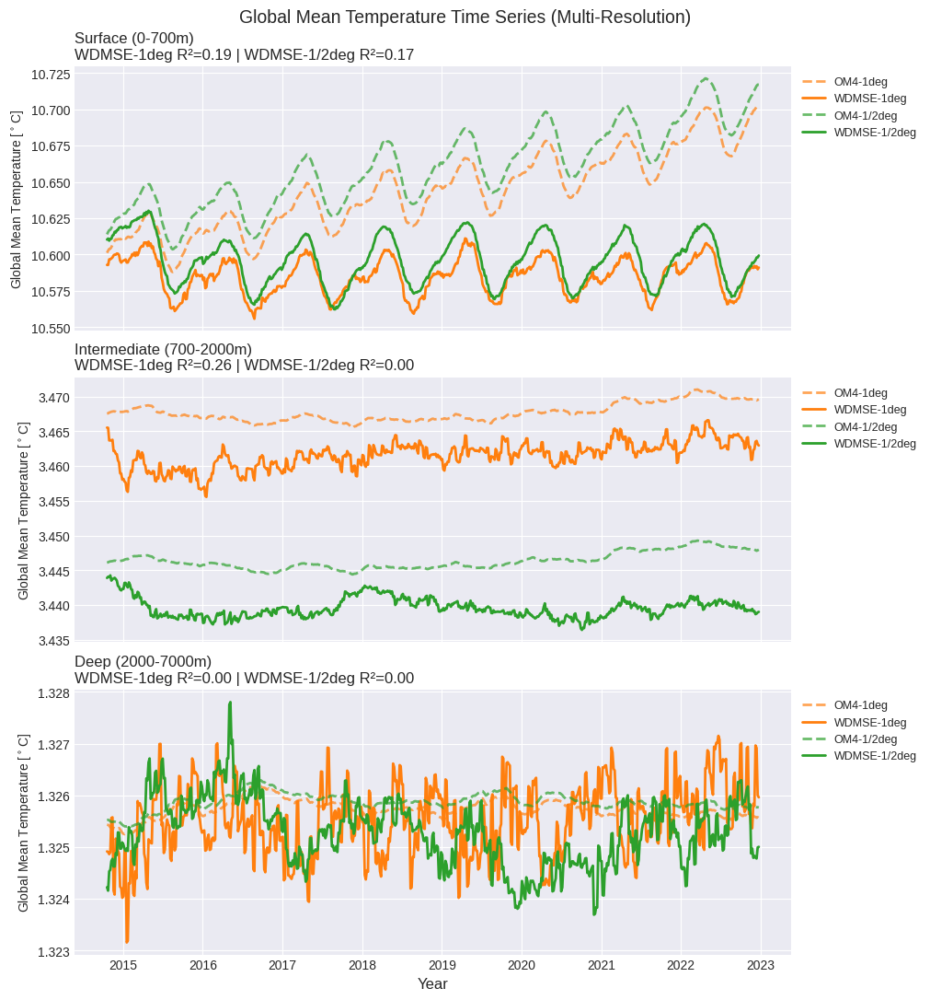

Generating Time Series for Salinity (Multi-Resolution)...


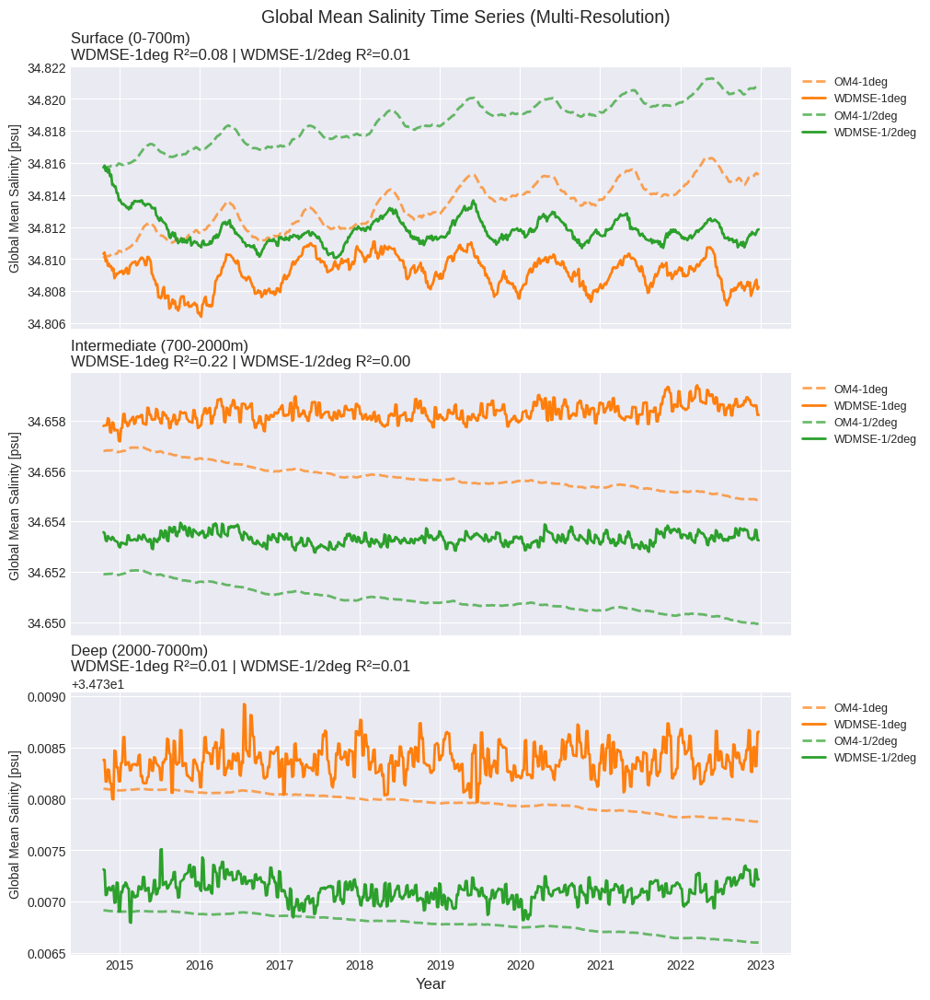


Generating Variance Comparison for thetao (Multi-Resolution)...


/pscratch/sd/y/yy6080/ocean_sim/lib/python3.10/site-packages/dask/array/numpy_compat.py:58: RuntimeWarning: invalid value encountered in divide
  x = np.divide(x1, x2, out)
/pscratch/sd/y/yy6080/ocean_sim/lib/python3.10/site-packages/dask/_task_spec.py:759: RuntimeWarning: invalid value encountered in divide
  return self.func(*new_argspec)
/pscratch/sd/y/yy6080/ocean_sim/lib/python3.10/site-packages/dask/array/numpy_compat.py:58: RuntimeWarning: invalid value encountered in divide
  x = np.divide(x1, x2, out)
/pscratch/sd/y/yy6080/ocean_sim/lib/python3.10/site-packages/dask/_task_spec.py:759: RuntimeWarning: invalid value encountered in divide
  return self.func(*new_argspec)
/pscratch/sd/y/yy6080/ocean_sim/lib/python3.10/site-packages/dask/array/numpy_compat.py:58: RuntimeWarning: invalid value encountered in divide
  x = np.divide(x1, x2, out)
/pscratch/sd/y/yy6080/ocean_sim/lib/python3.10/site-packages/dask/_task_spec.py:759: RuntimeWarning: invalid value encountered in divide
  re

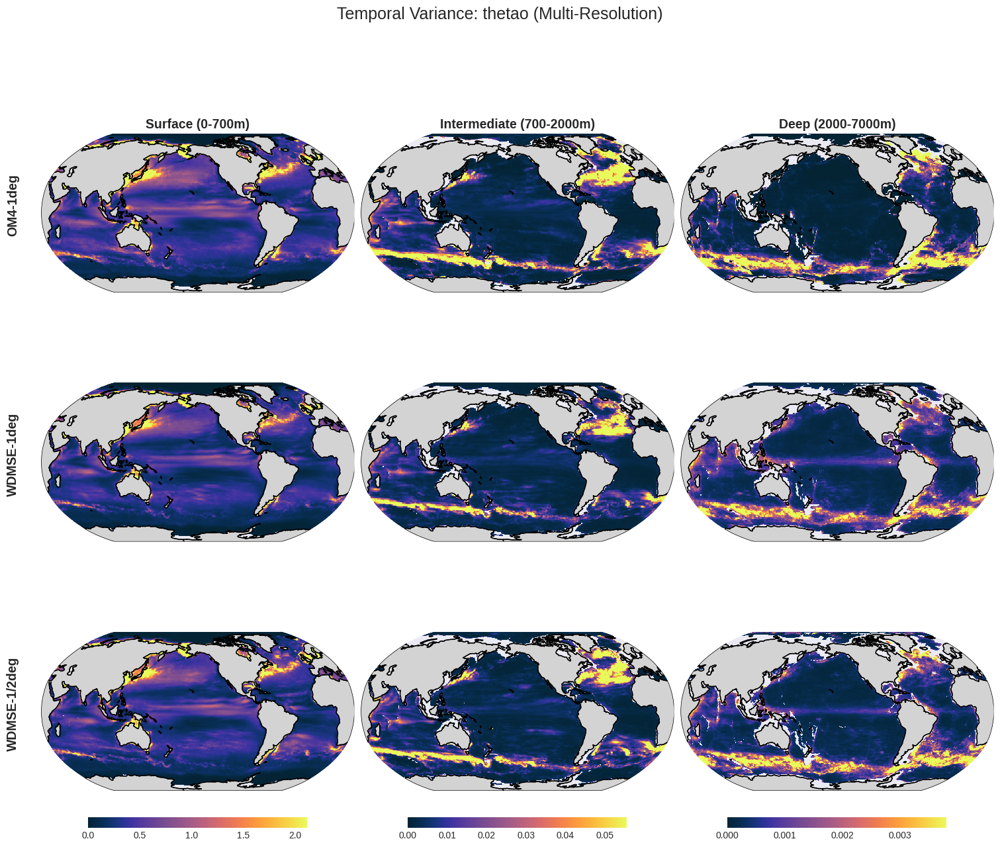


Generating Variance Comparison for so (Multi-Resolution)...


/pscratch/sd/y/yy6080/ocean_sim/lib/python3.10/site-packages/dask/array/numpy_compat.py:58: RuntimeWarning: invalid value encountered in divide
  x = np.divide(x1, x2, out)
/pscratch/sd/y/yy6080/ocean_sim/lib/python3.10/site-packages/dask/_task_spec.py:759: RuntimeWarning: invalid value encountered in divide
  return self.func(*new_argspec)
/pscratch/sd/y/yy6080/ocean_sim/lib/python3.10/site-packages/dask/array/numpy_compat.py:58: RuntimeWarning: invalid value encountered in divide
  x = np.divide(x1, x2, out)
/pscratch/sd/y/yy6080/ocean_sim/lib/python3.10/site-packages/dask/_task_spec.py:759: RuntimeWarning: invalid value encountered in divide
  return self.func(*new_argspec)
/pscratch/sd/y/yy6080/ocean_sim/lib/python3.10/site-packages/dask/array/numpy_compat.py:58: RuntimeWarning: invalid value encountered in divide
  x = np.divide(x1, x2, out)
/pscratch/sd/y/yy6080/ocean_sim/lib/python3.10/site-packages/dask/_task_spec.py:759: RuntimeWarning: invalid value encountered in divide
  re

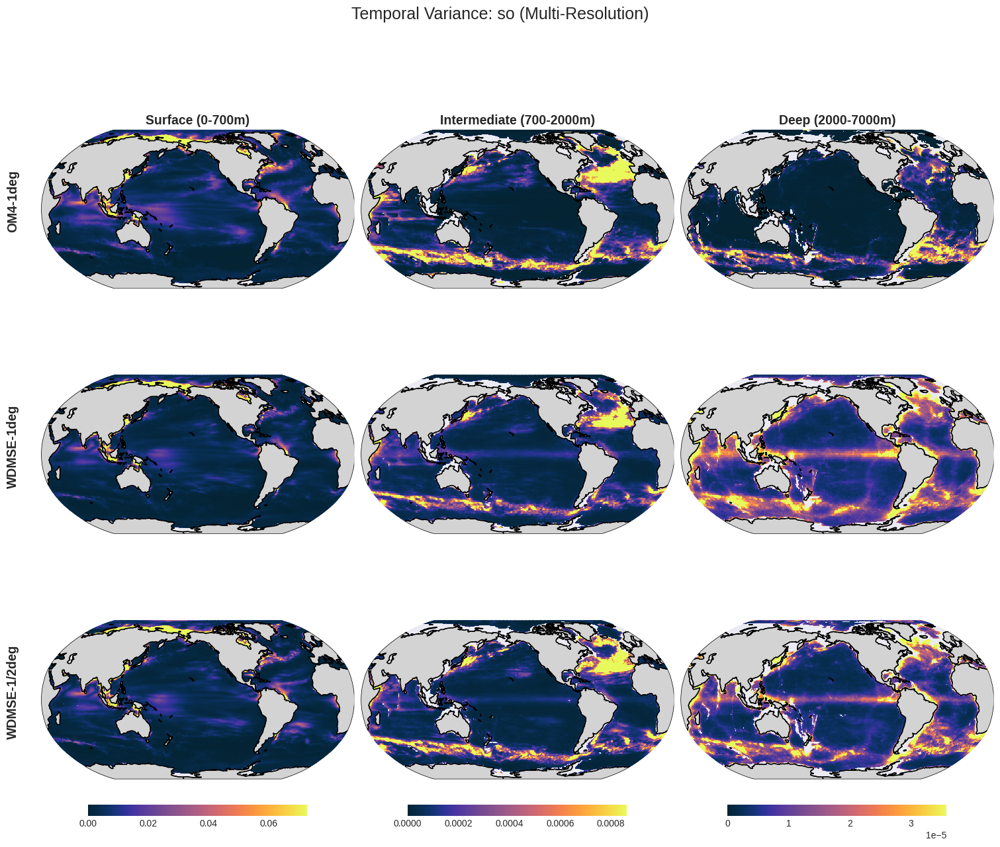


All plots generated successfully in: /global/u2/y/yy6080/workspace/Ocean_Emulator_Workspace/Ocean_Emulator/viz_jupyter/Emulator_Evaluation_Figures_1deg_All_New


In [64]:

# --- Run Plots ---
print("\nStarting Plotting Sequence...")

from functions import *

# 6. Time Series (Thetao)
plot_mean_timeseries_comparison_together(
    emulators_to_analyze, 
    variable_name='thetao', 
    var_units='$^\\circ$C', 
    var_label='Temperature',
    output_dir=OUTPUT_DIR
)

# 7. Time Series (Salinity)
plot_mean_timeseries_comparison_together(
    emulators_to_analyze, 
    variable_name='so', 
    var_units='psu', 
    var_label='Salinity',
    output_dir=OUTPUT_DIR
)

plot_variance_comparison_together(
    emulators_to_analyze, 
    variable_name='thetao', 
    units='$^\\circ$C',
    output_dir=OUTPUT_DIR,
    colorbar_fix = True
)

plot_variance_comparison_together(
    emulators_to_analyze, 
    variable_name='so',
    units='psu',
    output_dir=OUTPUT_DIR,
    colorbar_fix = True
)    
print(f"\nAll plots generated successfully in: {os.path.abspath(OUTPUT_DIR)}")

Here we look at how the ocean takes up heat over the inference rollout. To remove the shorter signal corresponding to seasonality, we remove climatology before computing this values. We look at this over the upper ocean, mid depth, and deep ocean as we expect signals of decreasing strength as we go to the deep ocean. We first compute OHC as  $$OHC(t) = \sum_{k \in Z} \sum_{j} \sum_{i} \rho_0 c_p \theta_{i,j,k,t} \Delta z_{k} A_{i,j}$$

We then compute the anomaly as $$\Delta OHC(t) = OHC(t)-OHC(0)$$

Here we look at the mean bias in each major ocean basin. This bias is computed as the difference between the mean state of the emulator and the mean state of OM4, as such this can average out a lot of errors.

In [ ]:
# # --- Execution ---

# from functions import *

# # basin_masks needs to be derived from 2D basin file or sliced
# plot_ohc_zonal_bias_comparison_together(
#     emulators_to_analyze, 
#     masks_list=masks_list,
#     colorbar_fix=True
# )

# # 1. Zonal Bias (Thetao)
# plot_zonal_bias_comparison_together(
#         emulators_to_analyze,
#          'thetao', 
#          '$^\\circ$C', 
#          masks_list,
#           OUTPUT_DIR,
#           colorbar_fix=True)


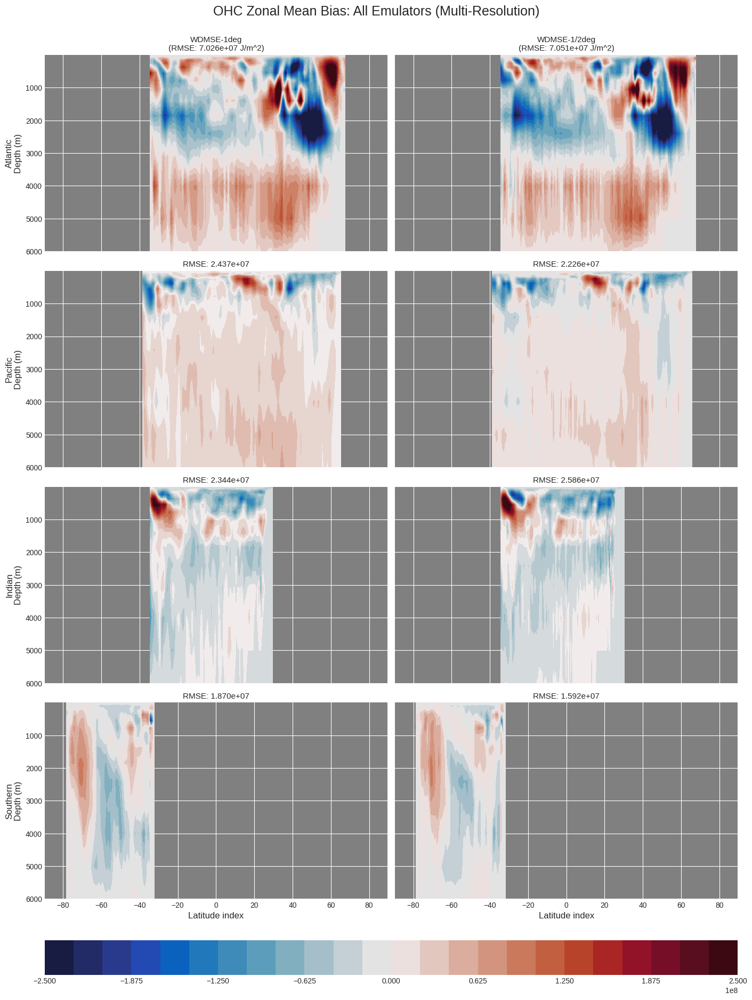

/pscratch/sd/y/yy6080/ocean_sim/lib/python3.10/site-packages/dask/_task_spec.py:759: RuntimeWarning: invalid value encountered in divide
  return self.func(*new_argspec)
/pscratch/sd/y/yy6080/ocean_sim/lib/python3.10/site-packages/dask/_task_spec.py:759: RuntimeWarning: invalid value encountered in divide
  return self.func(*new_argspec)
/pscratch/sd/y/yy6080/ocean_sim/lib/python3.10/site-packages/dask/_task_spec.py:759: RuntimeWarning: invalid value encountered in divide
  return self.func(*new_argspec)
/pscratch/sd/y/yy6080/ocean_sim/lib/python3.10/site-packages/dask/_task_spec.py:759: RuntimeWarning: invalid value encountered in divide
  return self.func(*new_argspec)
/pscratch/sd/y/yy6080/ocean_sim/lib/python3.10/site-packages/dask/_task_spec.py:759: RuntimeWarning: invalid value encountered in divide
  return self.func(*new_argspec)
/pscratch/sd/y/yy6080/ocean_sim/lib/python3.10/site-packages/dask/_task_spec.py:759: RuntimeWarning: invalid value encountered in divide
  return self

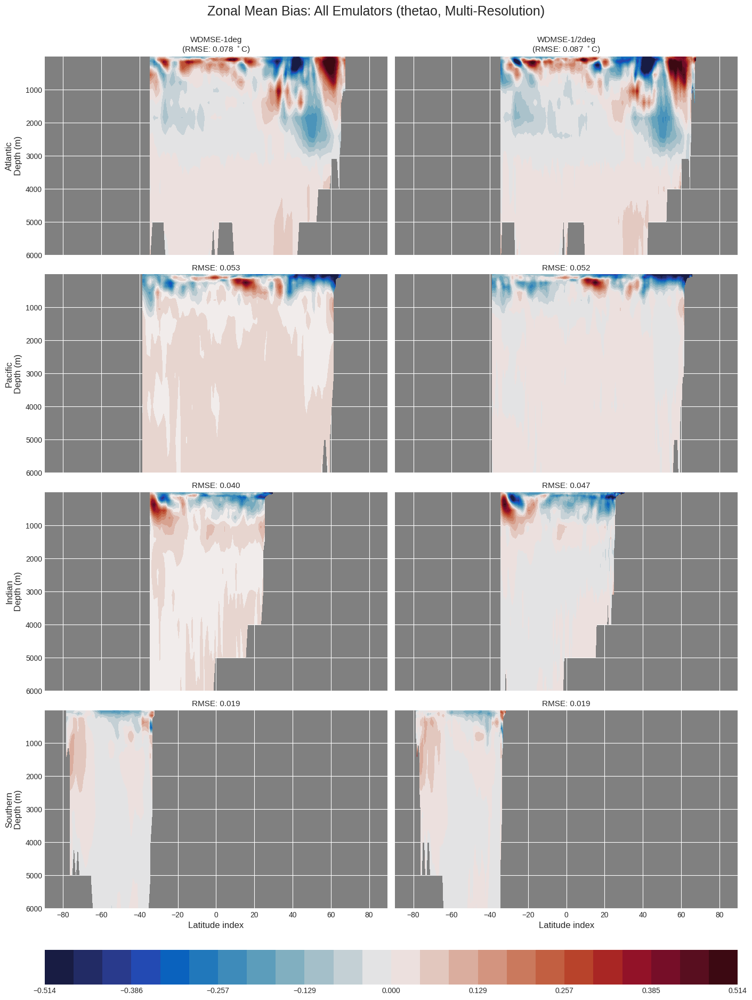

In [66]:
# --- Execution ---

from functions import *

# basin_masks needs to be derived from 2D basin file or sliced
plot_ohc_zonal_bias_ocean_comparison_together(
    emulators_to_analyze, 
    masks_list = masks_list,
    colorbar_fix=True
)

# 1. Zonal Bias (Thetao)
plot_zonal_bias_ocean_comparison_together(
    emulators_to_analyze, 
    'thetao', 
    '$^\\circ$C', 
    masks_list, 
    OUTPUT_DIR,
    colorbar_fix=True
)

/pscratch/sd/y/yy6080/ocean_sim/lib/python3.10/site-packages/dask/_task_spec.py:759: RuntimeWarning: invalid value encountered in divide
  return self.func(*new_argspec)
/pscratch/sd/y/yy6080/ocean_sim/lib/python3.10/site-packages/dask/_task_spec.py:759: RuntimeWarning: invalid value encountered in divide
  return self.func(*new_argspec)
/pscratch/sd/y/yy6080/ocean_sim/lib/python3.10/site-packages/dask/_task_spec.py:759: RuntimeWarning: invalid value encountered in divide
  return self.func(*new_argspec)
/pscratch/sd/y/yy6080/ocean_sim/lib/python3.10/site-packages/dask/_task_spec.py:759: RuntimeWarning: invalid value encountered in divide
  return self.func(*new_argspec)
/pscratch/sd/y/yy6080/ocean_sim/lib/python3.10/site-packages/dask/_task_spec.py:759: RuntimeWarning: invalid value encountered in divide
  return self.func(*new_argspec)
/pscratch/sd/y/yy6080/ocean_sim/lib/python3.10/site-packages/dask/_task_spec.py:759: RuntimeWarning: invalid value encountered in divide
  return self

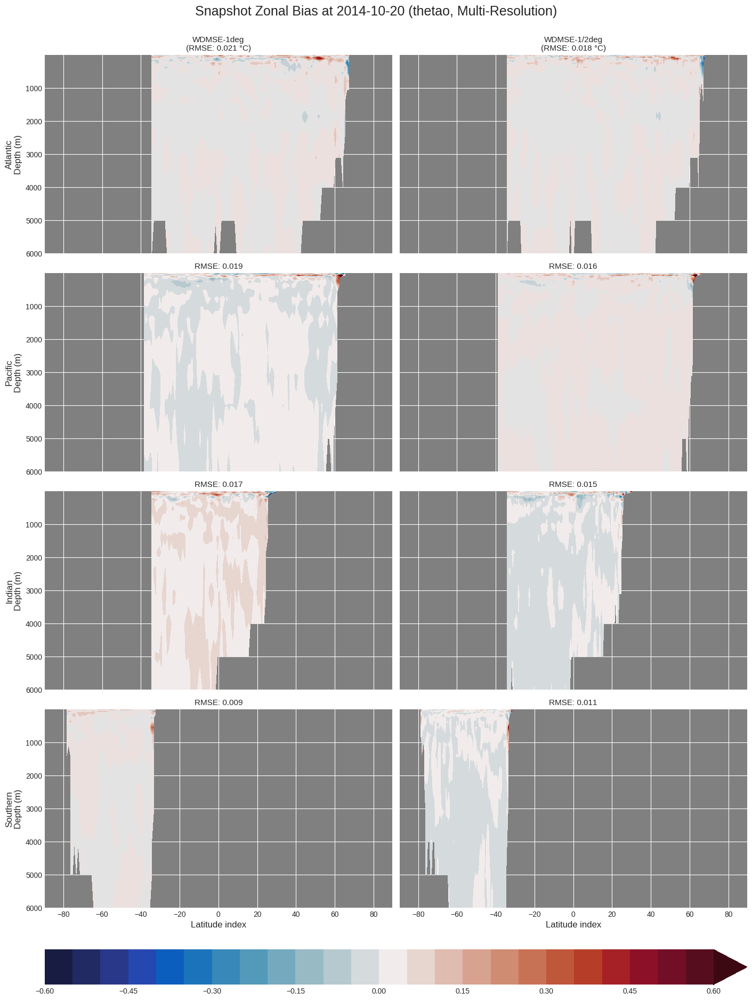

/pscratch/sd/y/yy6080/ocean_sim/lib/python3.10/site-packages/dask/_task_spec.py:759: RuntimeWarning: invalid value encountered in divide
  return self.func(*new_argspec)
/pscratch/sd/y/yy6080/ocean_sim/lib/python3.10/site-packages/dask/_task_spec.py:759: RuntimeWarning: invalid value encountered in divide
  return self.func(*new_argspec)
/pscratch/sd/y/yy6080/ocean_sim/lib/python3.10/site-packages/dask/_task_spec.py:759: RuntimeWarning: invalid value encountered in divide
  return self.func(*new_argspec)
/pscratch/sd/y/yy6080/ocean_sim/lib/python3.10/site-packages/dask/_task_spec.py:759: RuntimeWarning: invalid value encountered in divide
  return self.func(*new_argspec)
/pscratch/sd/y/yy6080/ocean_sim/lib/python3.10/site-packages/dask/_task_spec.py:759: RuntimeWarning: invalid value encountered in divide
  return self.func(*new_argspec)
/pscratch/sd/y/yy6080/ocean_sim/lib/python3.10/site-packages/dask/_task_spec.py:759: RuntimeWarning: invalid value encountered in divide
  return self

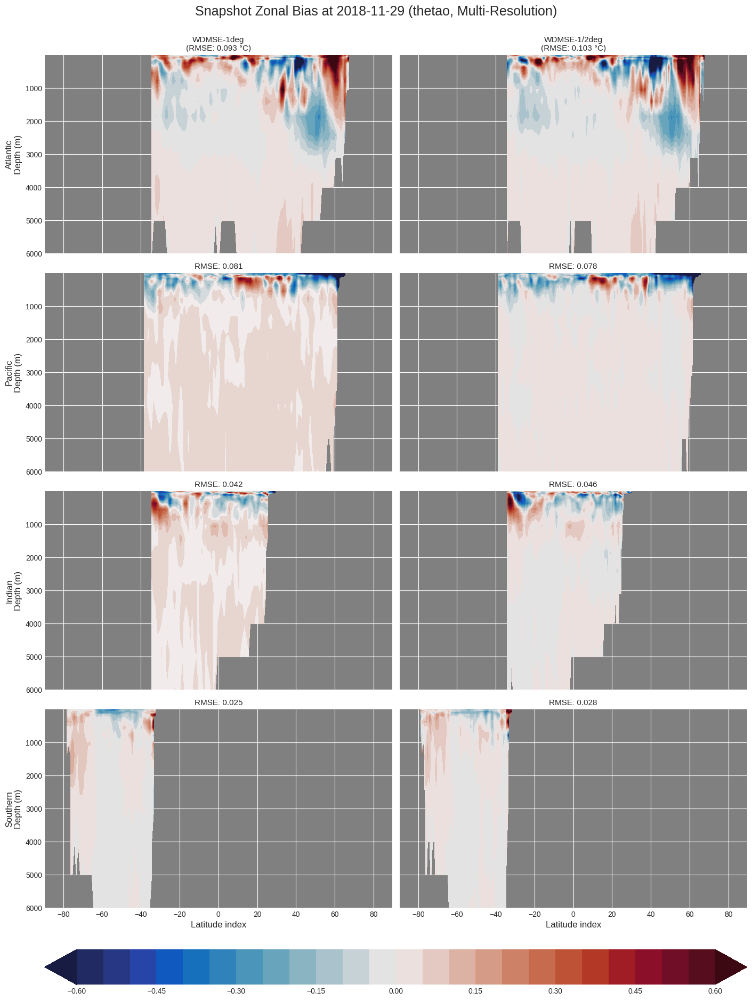

/pscratch/sd/y/yy6080/ocean_sim/lib/python3.10/site-packages/dask/_task_spec.py:759: RuntimeWarning: invalid value encountered in divide
  return self.func(*new_argspec)
/pscratch/sd/y/yy6080/ocean_sim/lib/python3.10/site-packages/dask/_task_spec.py:759: RuntimeWarning: invalid value encountered in divide
  return self.func(*new_argspec)
/pscratch/sd/y/yy6080/ocean_sim/lib/python3.10/site-packages/dask/_task_spec.py:759: RuntimeWarning: invalid value encountered in divide
  return self.func(*new_argspec)
/pscratch/sd/y/yy6080/ocean_sim/lib/python3.10/site-packages/dask/_task_spec.py:759: RuntimeWarning: invalid value encountered in divide
  return self.func(*new_argspec)
/pscratch/sd/y/yy6080/ocean_sim/lib/python3.10/site-packages/dask/_task_spec.py:759: RuntimeWarning: invalid value encountered in divide
  return self.func(*new_argspec)
/pscratch/sd/y/yy6080/ocean_sim/lib/python3.10/site-packages/dask/_task_spec.py:759: RuntimeWarning: invalid value encountered in divide
  return self

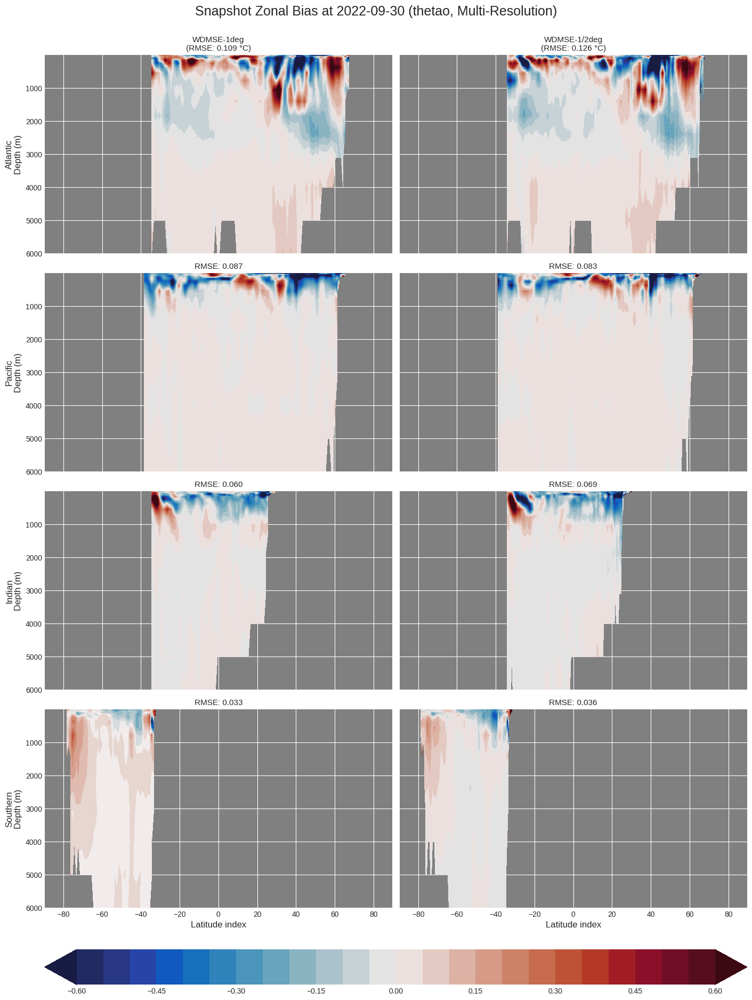

Exception ignored in: <function WeakSet.__init__.<locals>._remove at 0x7f2f9c2881f0>
Traceback (most recent call last):
  File "/pscratch/sd/y/yy6080/ocean_sim/lib/python3.10/_weakrefset.py", line 39, in _remove
    def _remove(item, selfref=ref(self)):
KeyboardInterrupt: 


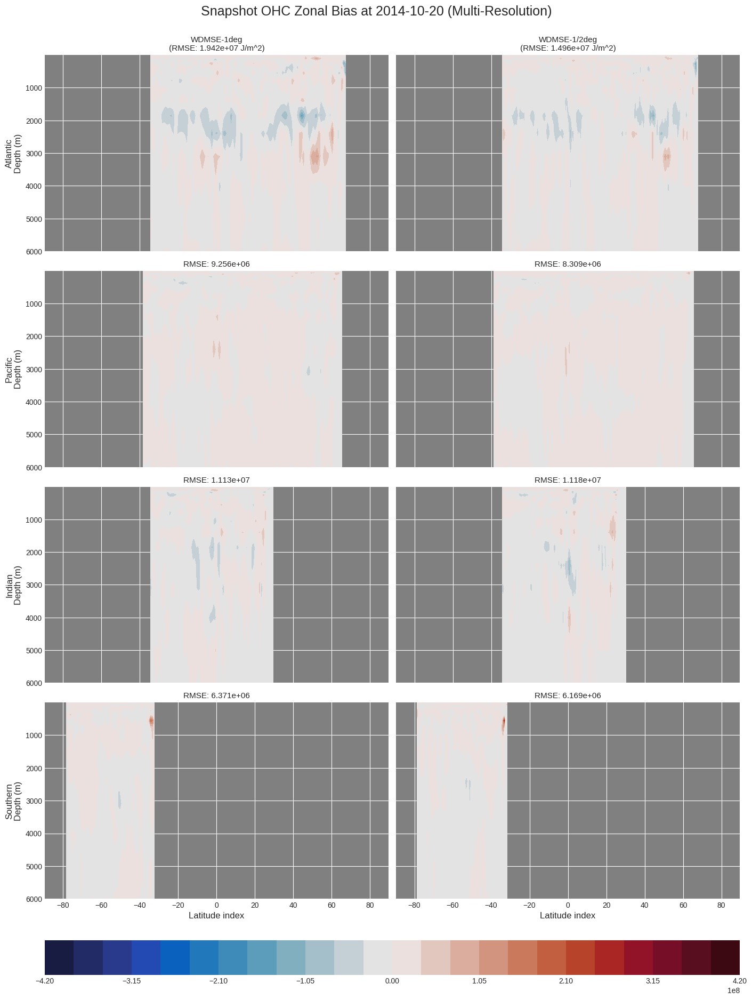

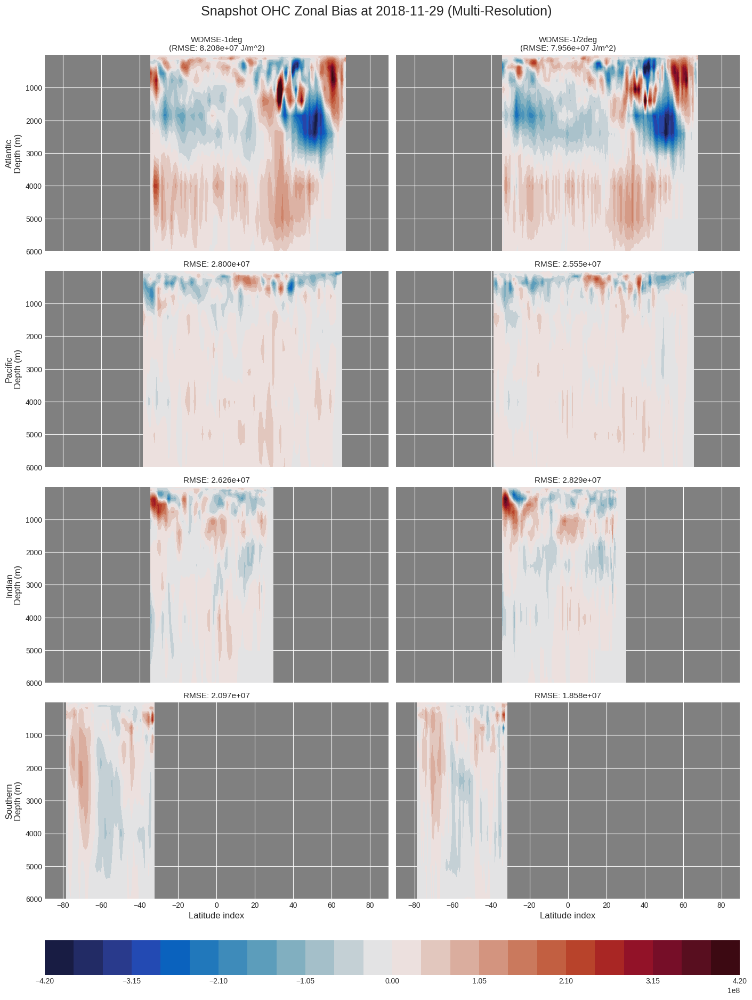

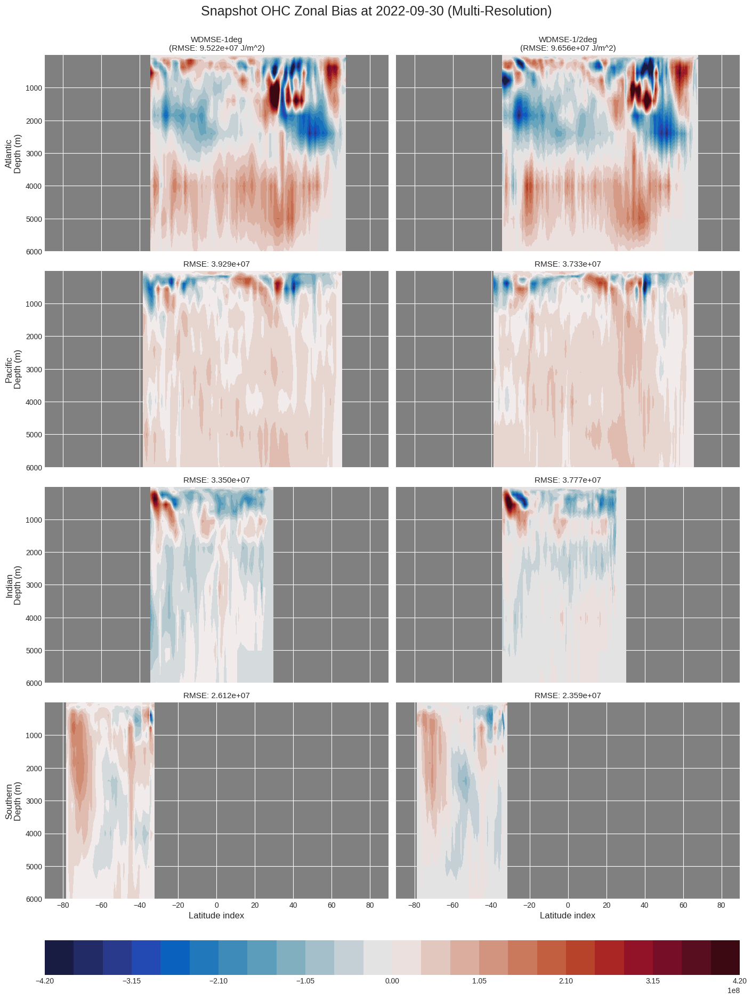

In [69]:
# --- Execution ---

from functions import *

plot_snapshot_zonal_bias_ocean_comparison_together(
    emulators_dict=emulators_to_analyze,
    variable_name='thetao',
    units='°C',
    masks_list=masks_list,
    TIME_INDICES=TIME_INDICES,
    colorbar_fix=True
)

plot_snapshot_ohc_zonal_bias_ocean_comparison_together(
    emulators_dict=emulators_to_analyze,
    masks_list=masks_list,
    TIME_INDICES=TIME_INDICES,
    colorbar_fix=True
)

This is the same bias as above, but seperated into depth levels rather than basins.

In [ ]:
from functions import *

Plotting some OHC maps


Generating OHC Mean Comparison (Multi-Resolution)...


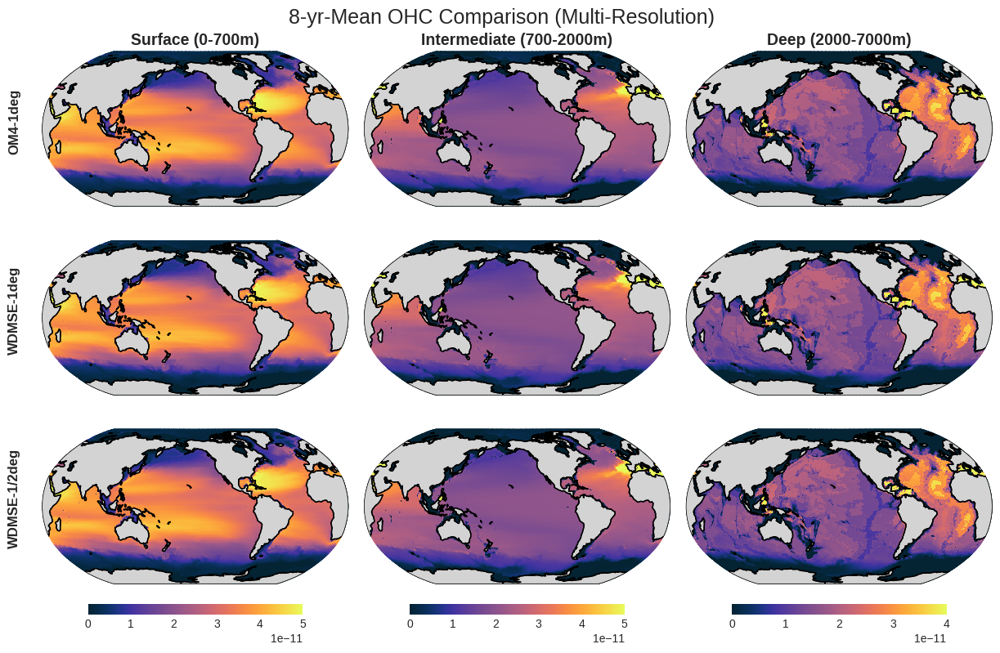

In [ ]:
# --- Execution ---
plot_ohc_mean_comparison_together(
    emulators_to_analyze,
    colorbar_fix=True
)


Generating Temperature Mean Comparison (Multi-Resolution)...


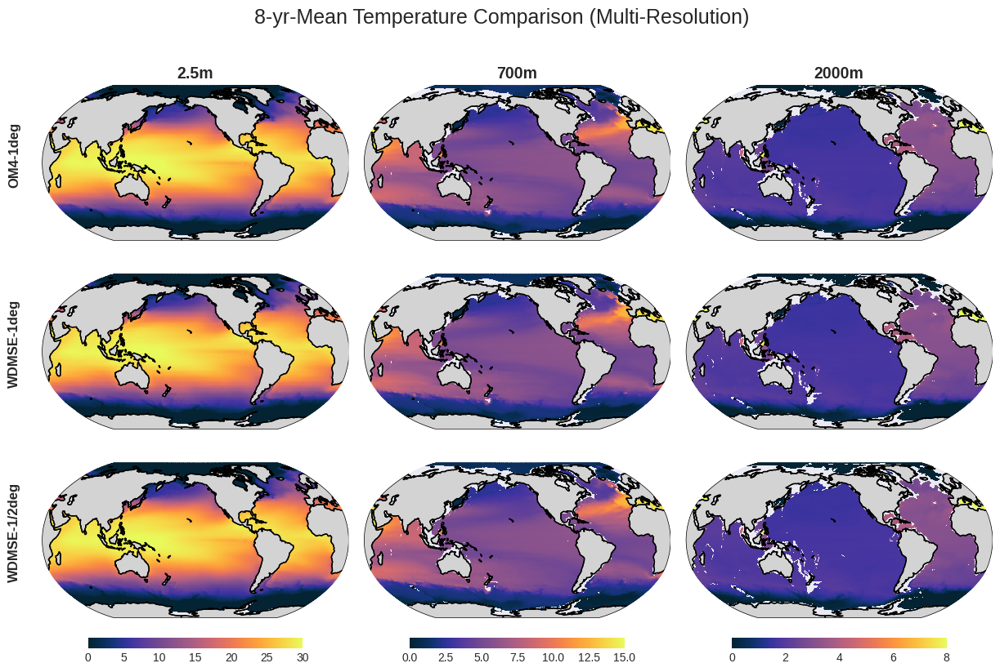

In [84]:
from functions import *
# --- Execution ---
plot_temperature_mean_comparison_together(
    emulators_to_analyze,
    colorbar_fix=True
)


Generating Zonal Mean Comparison for thetao (Multi-Resolution)...


/pscratch/sd/y/yy6080/ocean_sim/lib/python3.10/site-packages/dask/_task_spec.py:759: RuntimeWarning: invalid value encountered in divide
  return self.func(*new_argspec)
/pscratch/sd/y/yy6080/ocean_sim/lib/python3.10/site-packages/dask/_task_spec.py:759: RuntimeWarning: invalid value encountered in divide
  return self.func(*new_argspec)
/pscratch/sd/y/yy6080/ocean_sim/lib/python3.10/site-packages/dask/_task_spec.py:759: RuntimeWarning: invalid value encountered in divide
  return self.func(*new_argspec)
/pscratch/sd/y/yy6080/ocean_sim/lib/python3.10/site-packages/dask/_task_spec.py:759: RuntimeWarning: invalid value encountered in divide
  return self.func(*new_argspec)
/pscratch/sd/y/yy6080/ocean_sim/lib/python3.10/site-packages/dask/_task_spec.py:759: RuntimeWarning: invalid value encountered in divide
  return self.func(*new_argspec)
/pscratch/sd/y/yy6080/ocean_sim/lib/python3.10/site-packages/dask/_task_spec.py:759: RuntimeWarning: invalid value encountered in divide
  return self

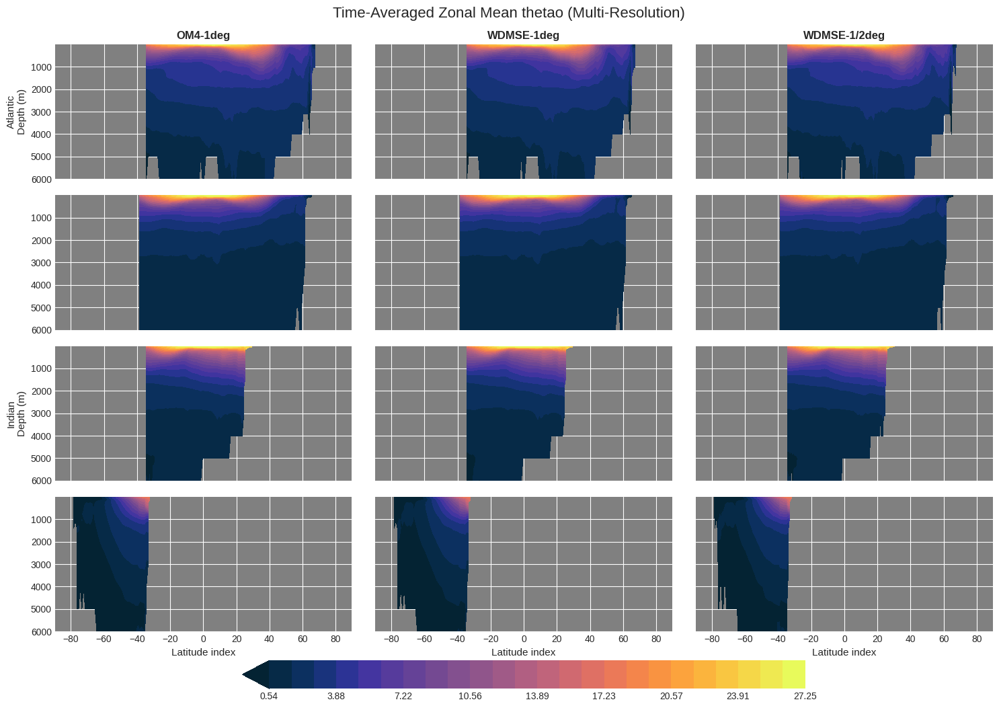

In [ ]:
from functions import *
# --- Execution ---

plot_zonal_mean_comparison_together(
    emulators_to_analyze, 
    variable_name='thetao', 
    units='$^\circ$C', 
    masks_list=masks_list,
    colorbar_fix=True
)


Generating OHC Zonal Mean Comparison (Multi-Resolution)...


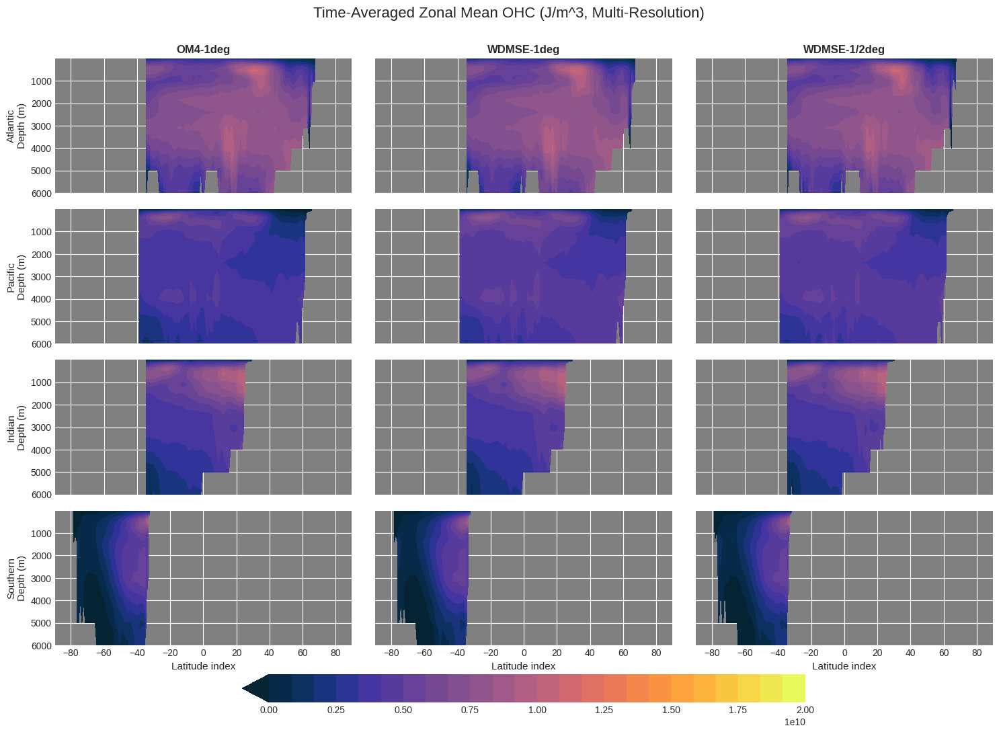

In [72]:
from functions import *

plot_ohc_zonal_mean_comparison_together(
    emulators_to_analyze, 
    variable_name='thetao', 
    units='$^\circ$C', 
    masks_list=masks_list,
    colorbar_fix=True 
)



Generating Zonal Snapshot Comparison for thetao (Multi-Resolution)...


/pscratch/sd/y/yy6080/ocean_sim/lib/python3.10/site-packages/dask/_task_spec.py:759: RuntimeWarning: invalid value encountered in divide
  return self.func(*new_argspec)
/pscratch/sd/y/yy6080/ocean_sim/lib/python3.10/site-packages/dask/_task_spec.py:759: RuntimeWarning: invalid value encountered in divide
  return self.func(*new_argspec)
/pscratch/sd/y/yy6080/ocean_sim/lib/python3.10/site-packages/dask/_task_spec.py:759: RuntimeWarning: invalid value encountered in divide
  return self.func(*new_argspec)
/pscratch/sd/y/yy6080/ocean_sim/lib/python3.10/site-packages/dask/_task_spec.py:759: RuntimeWarning: invalid value encountered in divide
  return self.func(*new_argspec)
/pscratch/sd/y/yy6080/ocean_sim/lib/python3.10/site-packages/dask/_task_spec.py:759: RuntimeWarning: invalid value encountered in divide
  return self.func(*new_argspec)
/pscratch/sd/y/yy6080/ocean_sim/lib/python3.10/site-packages/dask/_task_spec.py:759: RuntimeWarning: invalid value encountered in divide
  return self

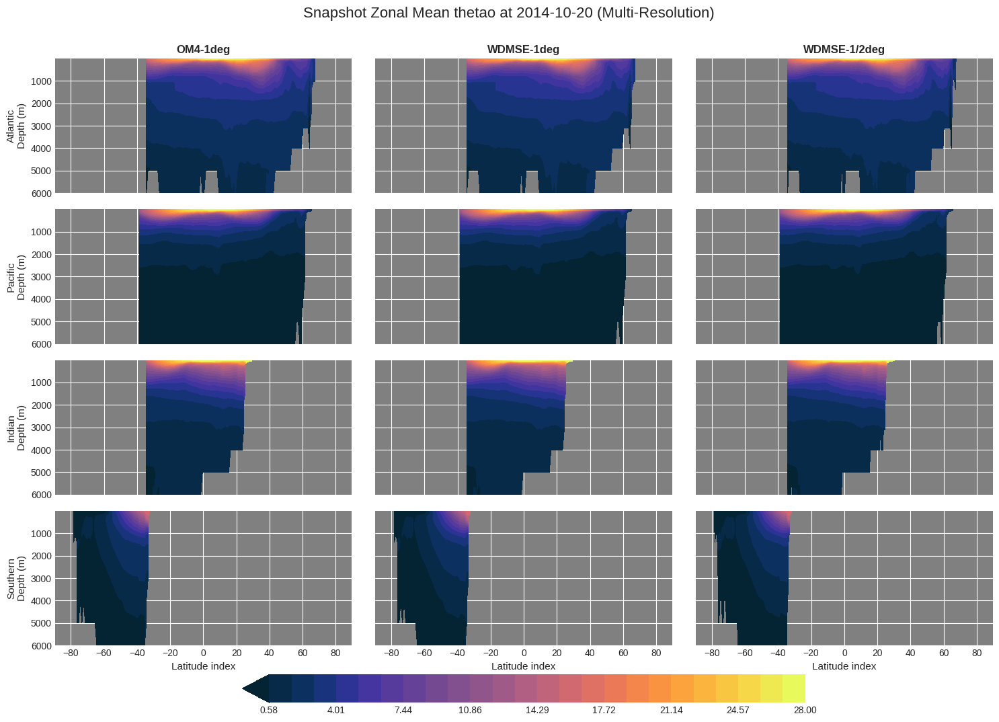

/pscratch/sd/y/yy6080/ocean_sim/lib/python3.10/site-packages/dask/_task_spec.py:759: RuntimeWarning: invalid value encountered in divide
  return self.func(*new_argspec)
/pscratch/sd/y/yy6080/ocean_sim/lib/python3.10/site-packages/dask/_task_spec.py:759: RuntimeWarning: invalid value encountered in divide
  return self.func(*new_argspec)
/pscratch/sd/y/yy6080/ocean_sim/lib/python3.10/site-packages/dask/_task_spec.py:759: RuntimeWarning: invalid value encountered in divide
  return self.func(*new_argspec)
/pscratch/sd/y/yy6080/ocean_sim/lib/python3.10/site-packages/dask/_task_spec.py:759: RuntimeWarning: invalid value encountered in divide
  return self.func(*new_argspec)
/pscratch/sd/y/yy6080/ocean_sim/lib/python3.10/site-packages/dask/_task_spec.py:759: RuntimeWarning: invalid value encountered in divide
  return self.func(*new_argspec)
/pscratch/sd/y/yy6080/ocean_sim/lib/python3.10/site-packages/dask/_task_spec.py:759: RuntimeWarning: invalid value encountered in divide
  return self

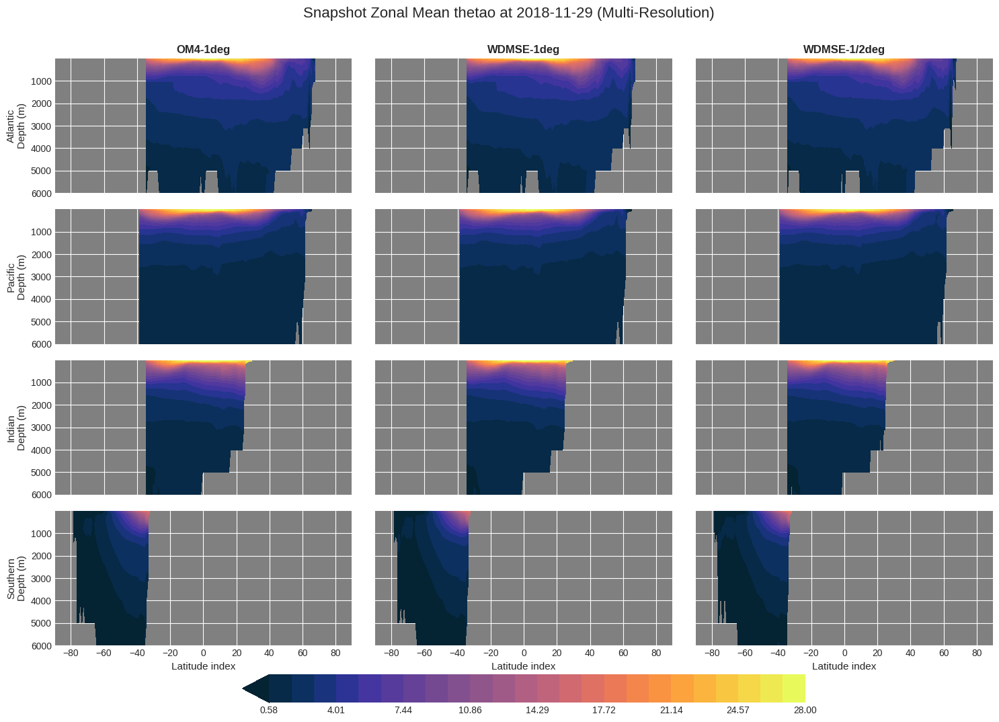

/pscratch/sd/y/yy6080/ocean_sim/lib/python3.10/site-packages/dask/_task_spec.py:759: RuntimeWarning: invalid value encountered in divide
  return self.func(*new_argspec)
/pscratch/sd/y/yy6080/ocean_sim/lib/python3.10/site-packages/dask/_task_spec.py:759: RuntimeWarning: invalid value encountered in divide
  return self.func(*new_argspec)
/pscratch/sd/y/yy6080/ocean_sim/lib/python3.10/site-packages/dask/_task_spec.py:759: RuntimeWarning: invalid value encountered in divide
  return self.func(*new_argspec)
/pscratch/sd/y/yy6080/ocean_sim/lib/python3.10/site-packages/dask/_task_spec.py:759: RuntimeWarning: invalid value encountered in divide
  return self.func(*new_argspec)
/pscratch/sd/y/yy6080/ocean_sim/lib/python3.10/site-packages/dask/_task_spec.py:759: RuntimeWarning: invalid value encountered in divide
  return self.func(*new_argspec)
/pscratch/sd/y/yy6080/ocean_sim/lib/python3.10/site-packages/dask/_task_spec.py:759: RuntimeWarning: invalid value encountered in divide
  return self

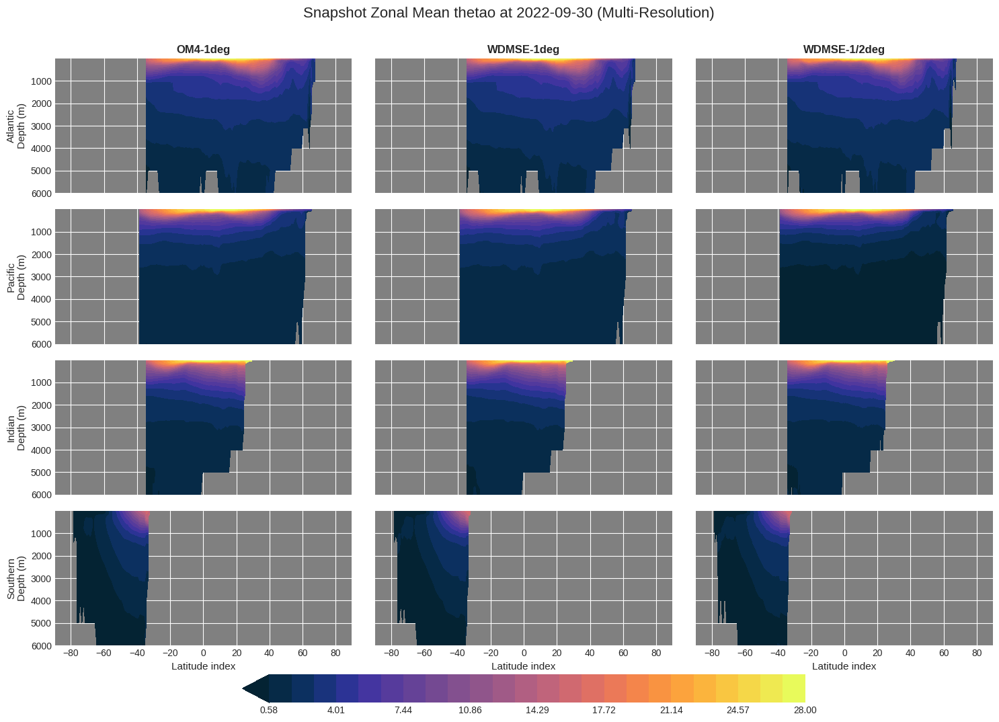

In [75]:
# --- Execution ---

from functions import *

plot_zonal_snapshot_comparison_together(
    emulators_to_analyze, 
    variable_name='thetao', 
    units='$^\circ$C', 
    masks_list=masks_list,
    time_indices = TIME_INDICES,
    colorbar_fix=True
)



Generating OHC Zonal Snapshot Comparison (Multi-Resolution)...


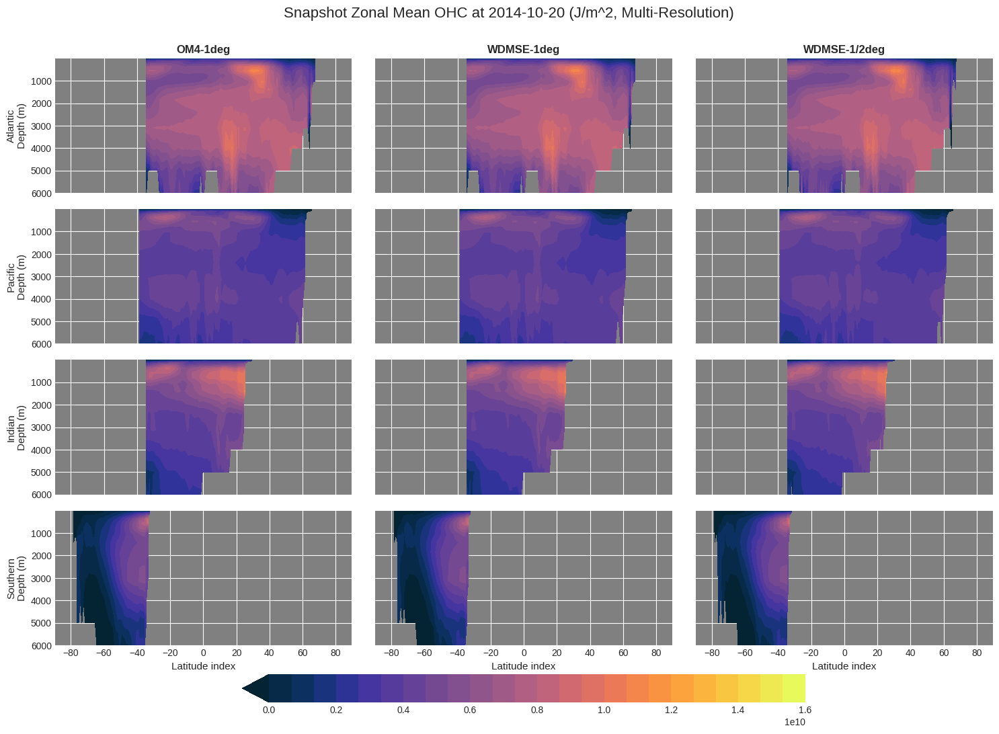

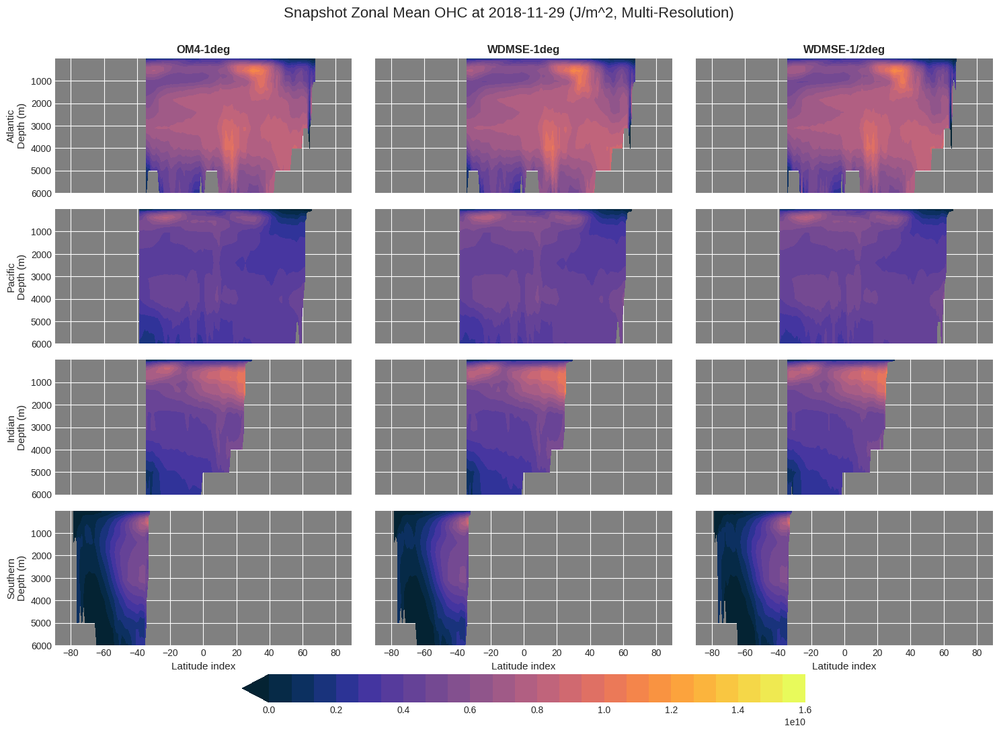

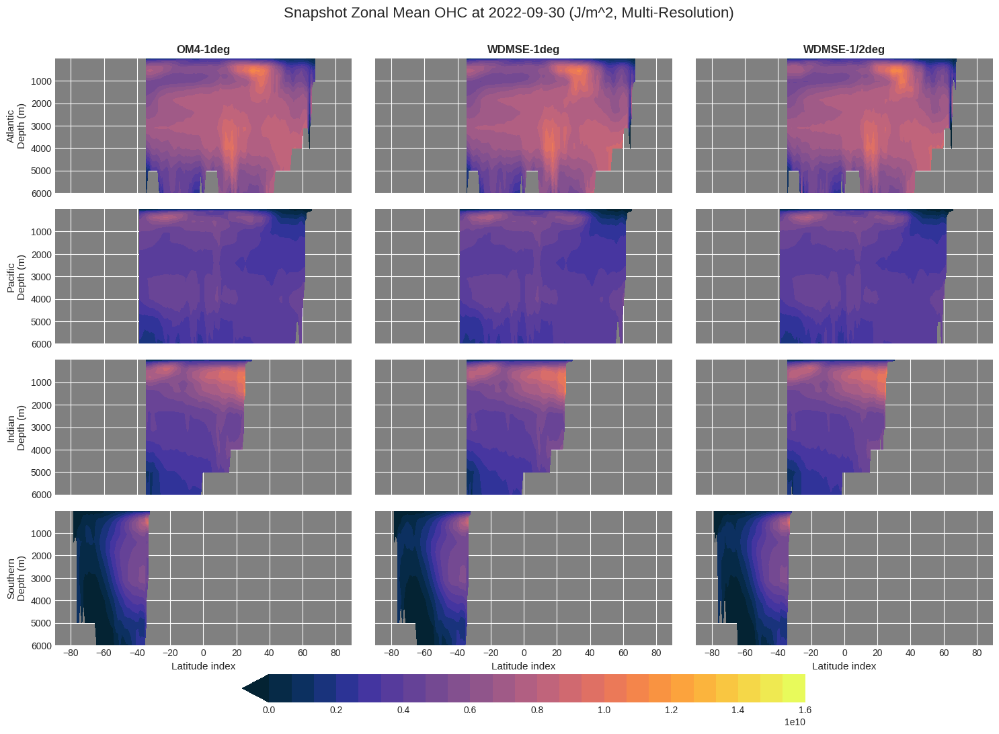

In [77]:
# --- Execution ---
from functions import *
plot_ohc_zonal_snapshot_comparison_together(
    emulators_to_analyze, 
    variable_name='thetao', 
    units='$^\circ$C', 
    masks_list=masks_list,
    TIME_INDICES = TIME_INDICES,
    colorbar_fix=True
)


Generating Zonal Mean Snapshot Comparison for thetao (Multi-Resolution)...


/pscratch/sd/y/yy6080/ocean_sim/lib/python3.10/site-packages/dask/_task_spec.py:759: RuntimeWarning: invalid value encountered in divide
  return self.func(*new_argspec)
/pscratch/sd/y/yy6080/ocean_sim/lib/python3.10/site-packages/dask/_task_spec.py:759: RuntimeWarning: invalid value encountered in divide
  return self.func(*new_argspec)
/pscratch/sd/y/yy6080/ocean_sim/lib/python3.10/site-packages/dask/_task_spec.py:759: RuntimeWarning: invalid value encountered in divide
  return self.func(*new_argspec)
/pscratch/sd/y/yy6080/ocean_sim/lib/python3.10/site-packages/dask/_task_spec.py:759: RuntimeWarning: invalid value encountered in divide
  return self.func(*new_argspec)
/pscratch/sd/y/yy6080/ocean_sim/lib/python3.10/site-packages/dask/_task_spec.py:759: RuntimeWarning: invalid value encountered in divide
  return self.func(*new_argspec)
/pscratch/sd/y/yy6080/ocean_sim/lib/python3.10/site-packages/dask/_task_spec.py:759: RuntimeWarning: invalid value encountered in divide
  return self

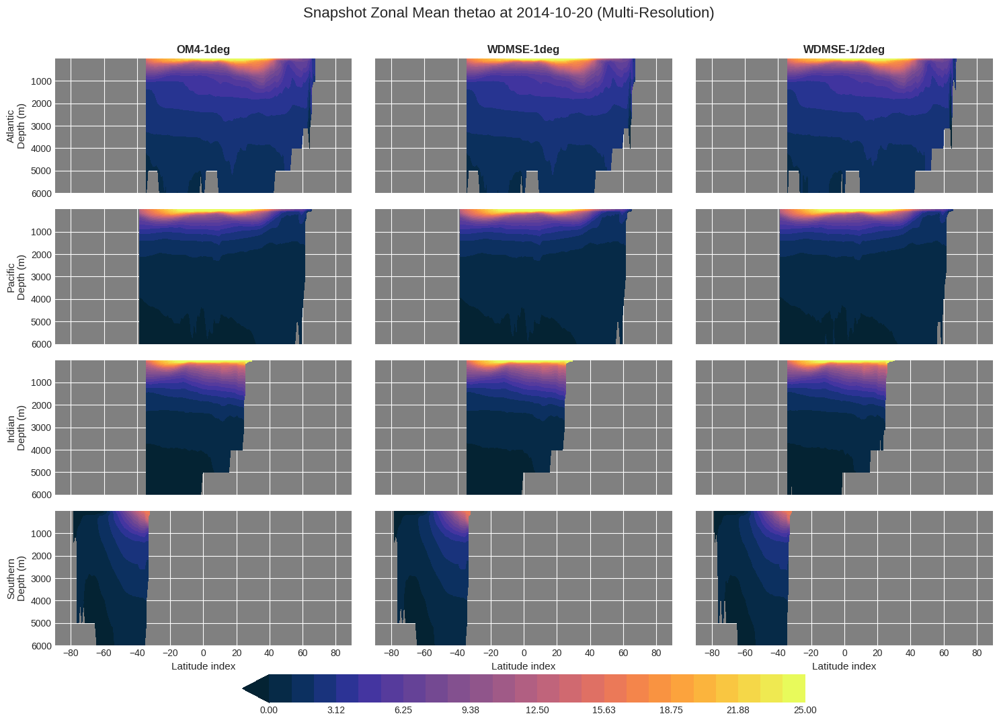

/pscratch/sd/y/yy6080/ocean_sim/lib/python3.10/site-packages/dask/_task_spec.py:759: RuntimeWarning: invalid value encountered in divide
  return self.func(*new_argspec)
/pscratch/sd/y/yy6080/ocean_sim/lib/python3.10/site-packages/dask/_task_spec.py:759: RuntimeWarning: invalid value encountered in divide
  return self.func(*new_argspec)
/pscratch/sd/y/yy6080/ocean_sim/lib/python3.10/site-packages/dask/_task_spec.py:759: RuntimeWarning: invalid value encountered in divide
  return self.func(*new_argspec)
/pscratch/sd/y/yy6080/ocean_sim/lib/python3.10/site-packages/dask/_task_spec.py:759: RuntimeWarning: invalid value encountered in divide
  return self.func(*new_argspec)
/pscratch/sd/y/yy6080/ocean_sim/lib/python3.10/site-packages/dask/_task_spec.py:759: RuntimeWarning: invalid value encountered in divide
  return self.func(*new_argspec)
/pscratch/sd/y/yy6080/ocean_sim/lib/python3.10/site-packages/dask/_task_spec.py:759: RuntimeWarning: invalid value encountered in divide
  return self

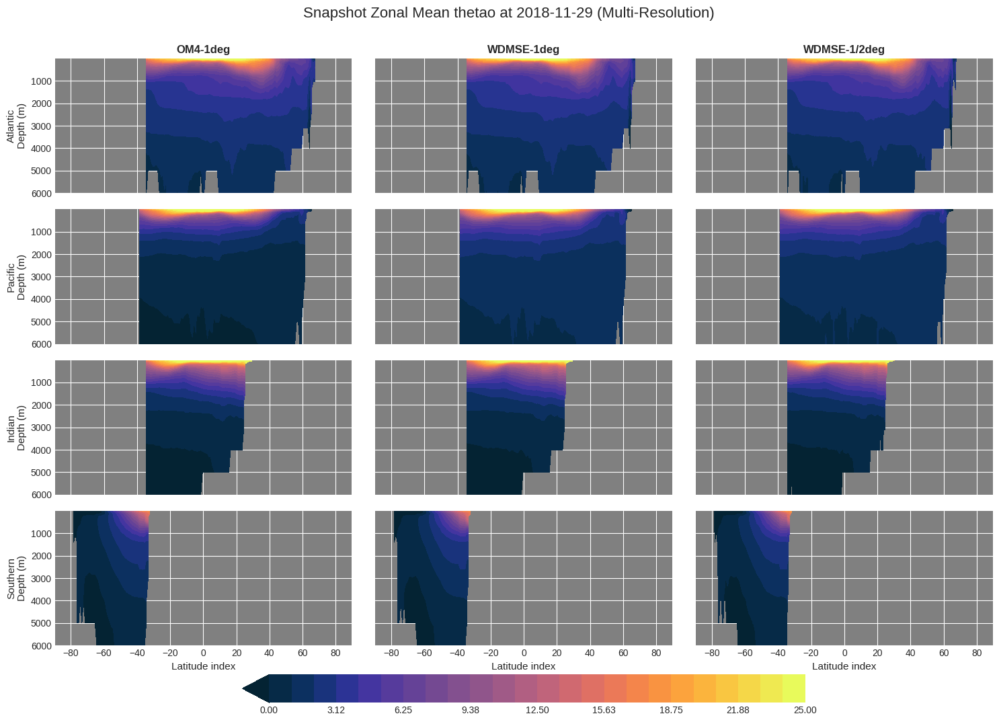

/pscratch/sd/y/yy6080/ocean_sim/lib/python3.10/site-packages/dask/_task_spec.py:759: RuntimeWarning: invalid value encountered in divide
  return self.func(*new_argspec)
/pscratch/sd/y/yy6080/ocean_sim/lib/python3.10/site-packages/dask/_task_spec.py:759: RuntimeWarning: invalid value encountered in divide
  return self.func(*new_argspec)
/pscratch/sd/y/yy6080/ocean_sim/lib/python3.10/site-packages/dask/_task_spec.py:759: RuntimeWarning: invalid value encountered in divide
  return self.func(*new_argspec)
/pscratch/sd/y/yy6080/ocean_sim/lib/python3.10/site-packages/dask/_task_spec.py:759: RuntimeWarning: invalid value encountered in divide
  return self.func(*new_argspec)
/pscratch/sd/y/yy6080/ocean_sim/lib/python3.10/site-packages/dask/_task_spec.py:759: RuntimeWarning: invalid value encountered in divide
  return self.func(*new_argspec)
/pscratch/sd/y/yy6080/ocean_sim/lib/python3.10/site-packages/dask/_task_spec.py:759: RuntimeWarning: invalid value encountered in divide
  return self

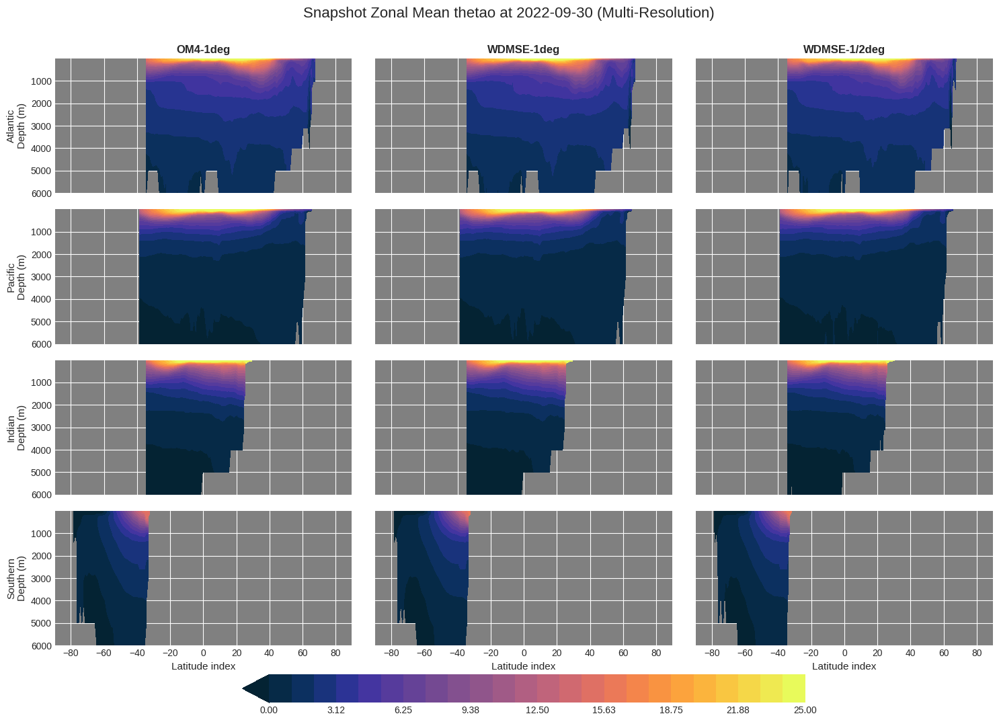

In [78]:

plot_zonal_mean_snapshot_comparison_together(
    emulators_dict=emulators_to_analyze,
    variable_name='thetao',
    units='°C',
    masks_list=masks_list,
    TIME_INDICES = TIME_INDICES,  # Your desired time indices
    colorbar_fix=True
)


Generating OHC Bias Comparison (Multi-Resolution)...


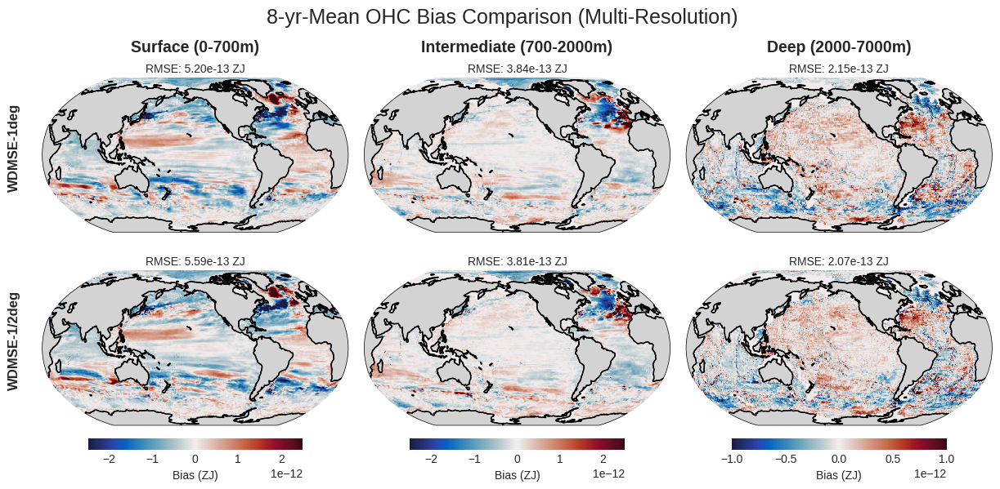

In [101]:
from functions import *

# --- Execution ---
plot_ohc_bias_comparison_together(emulators_to_analyze,colorbar_fix=True)



Generating Temperature Bias Comparison (Multi-Resolution)...


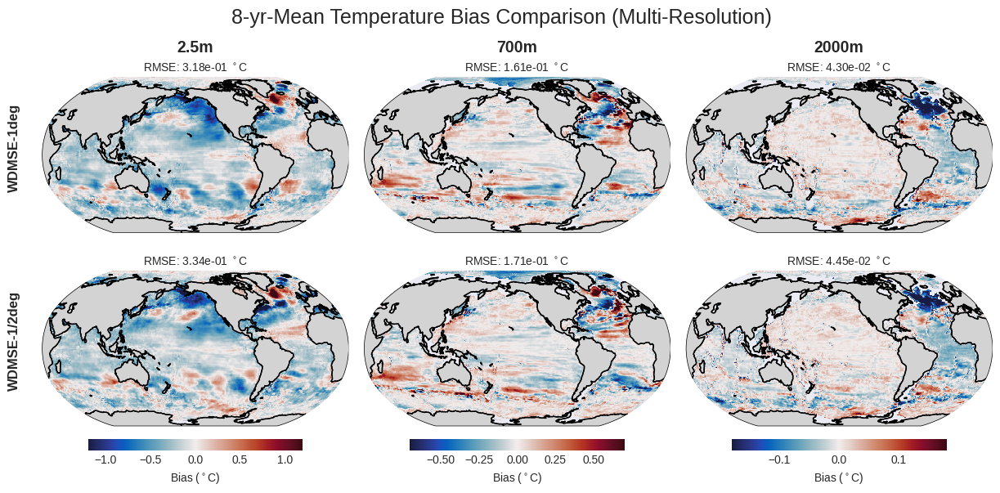

In [102]:
from functions import *
# --- Execution ---
plot_temperature_bias_comparison_together(emulators_to_analyze,colorbar_fix=True)

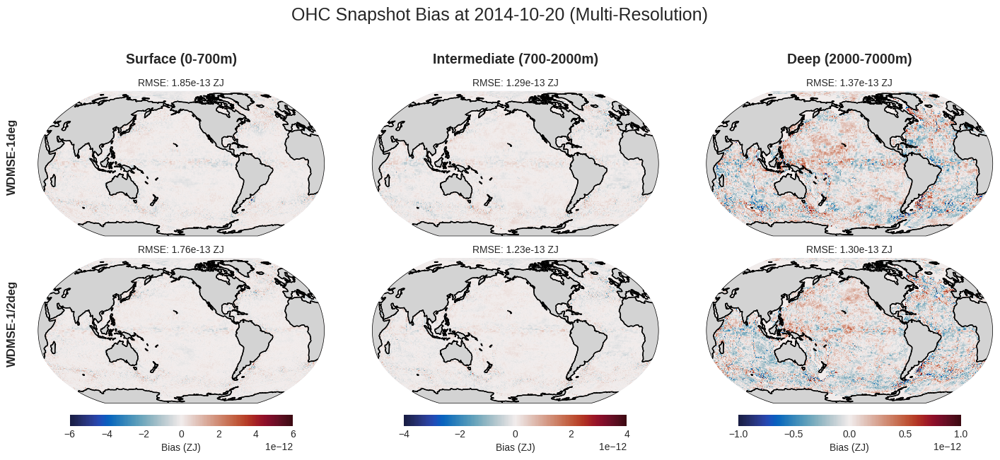

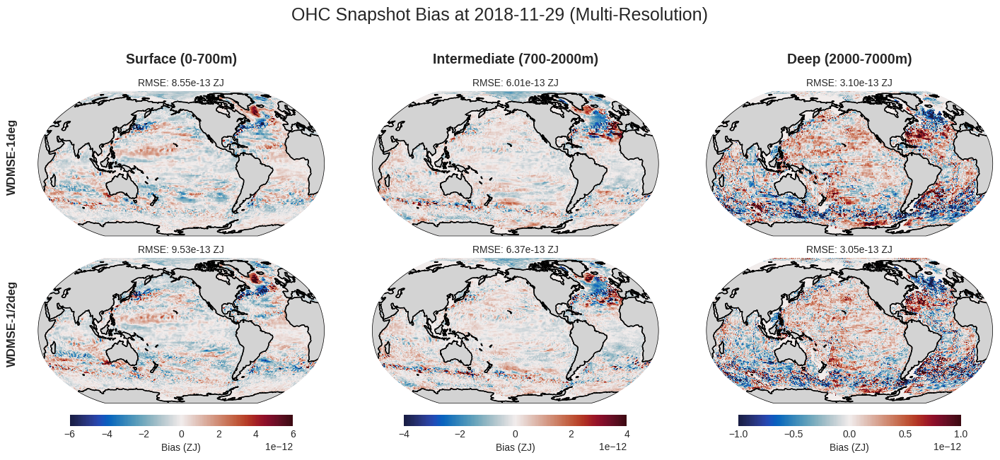

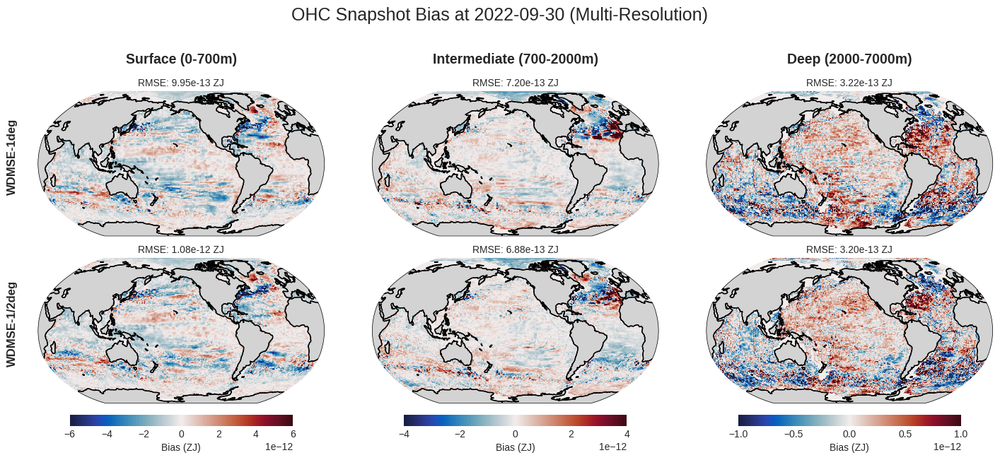

In [99]:

from functions import *
plot_ohc_snapshot_bias_comparison_together(emulators_to_analyze, TIME_INDICES, colorbar_fix=True)

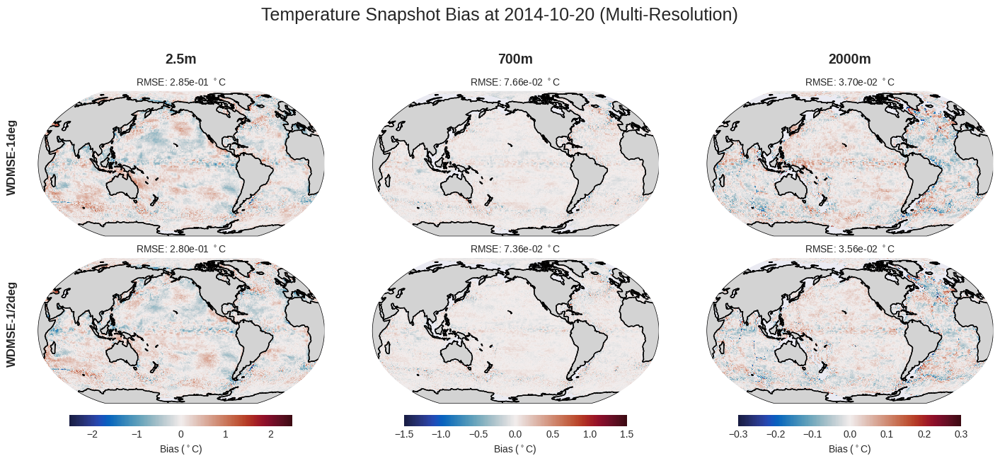

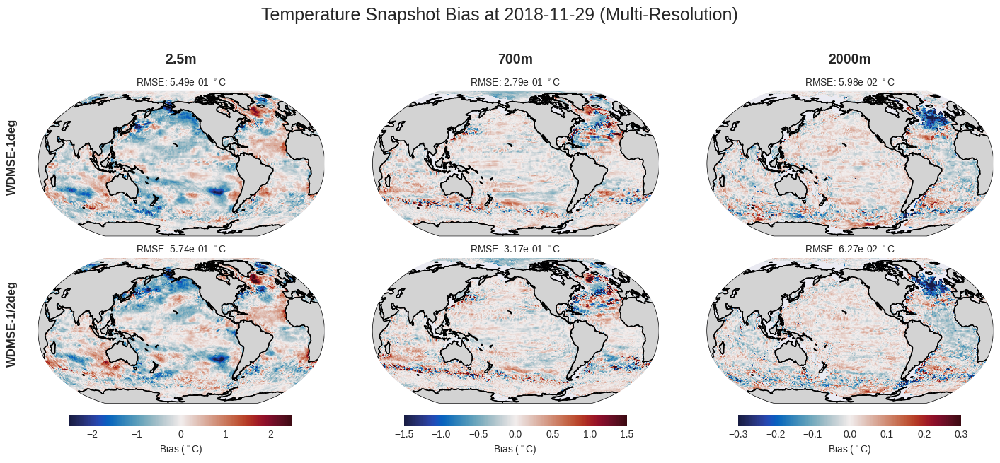

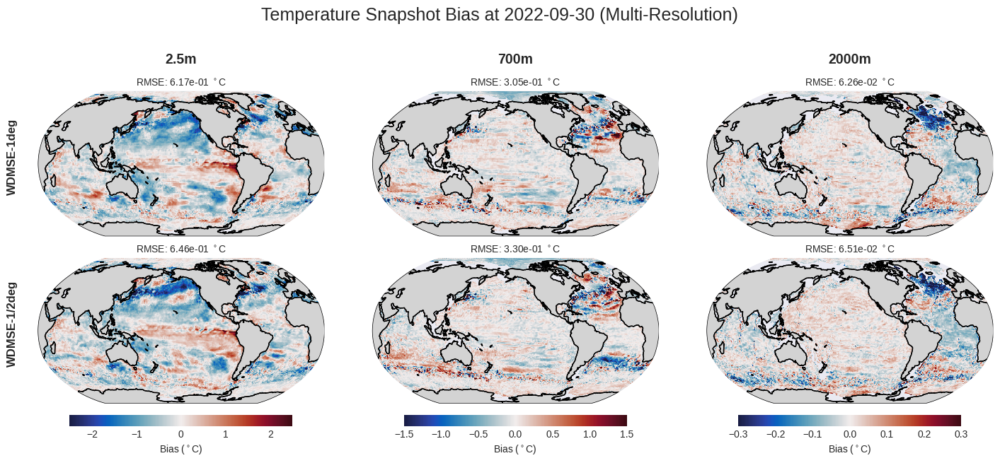

In [100]:
from functions import *
plot_temperature_snapshot_bias_comparison_together(emulators_to_analyze, TIME_INDICES, colorbar_fix=True)



Generating Snapshot Comparison for Temperature (Multi-Resolution, Multi-Depth)...


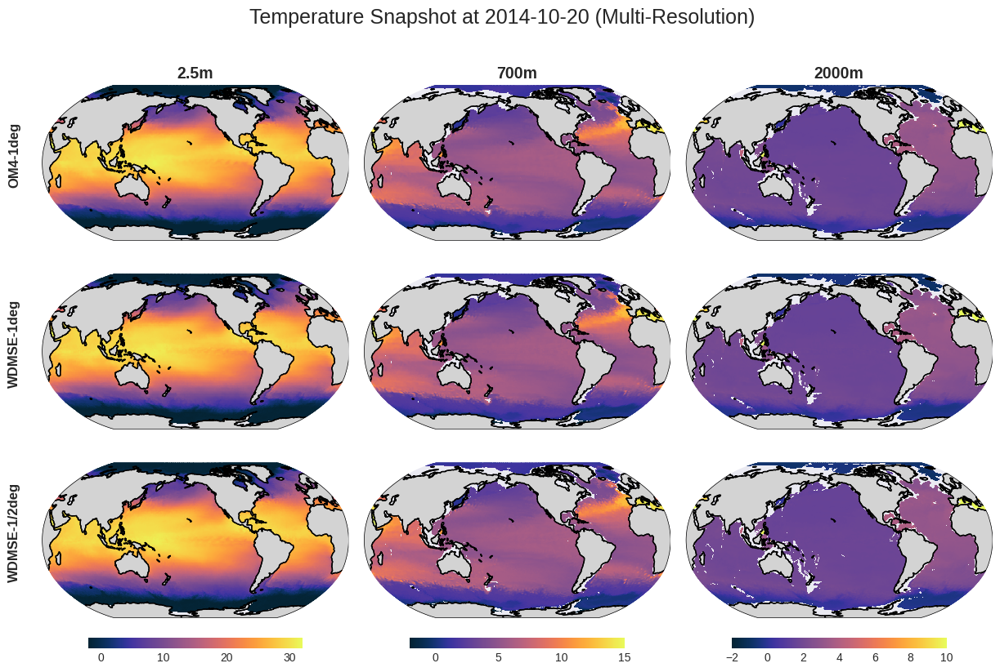

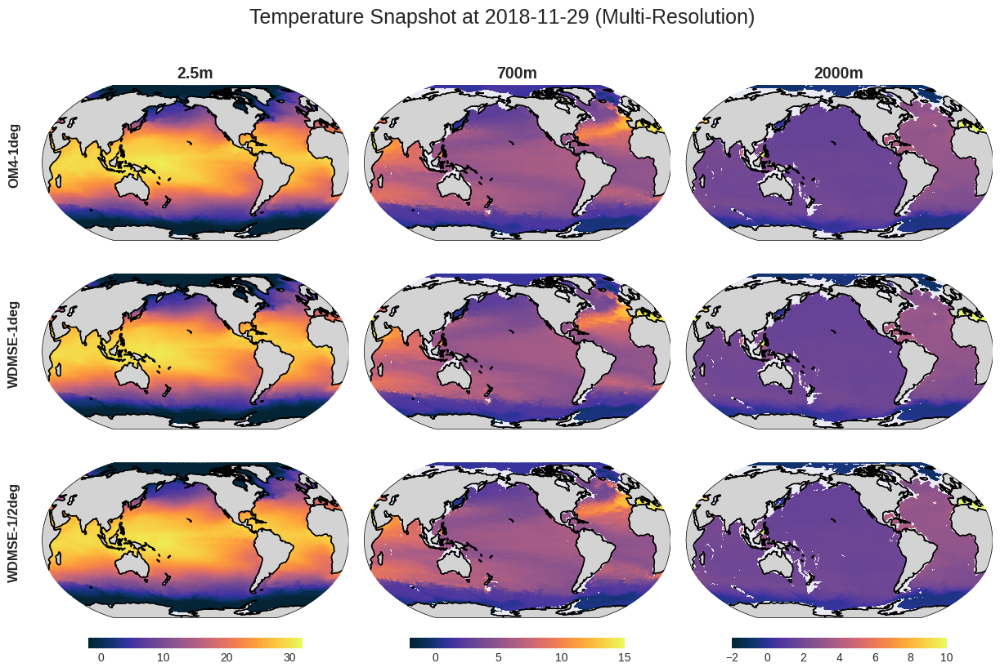

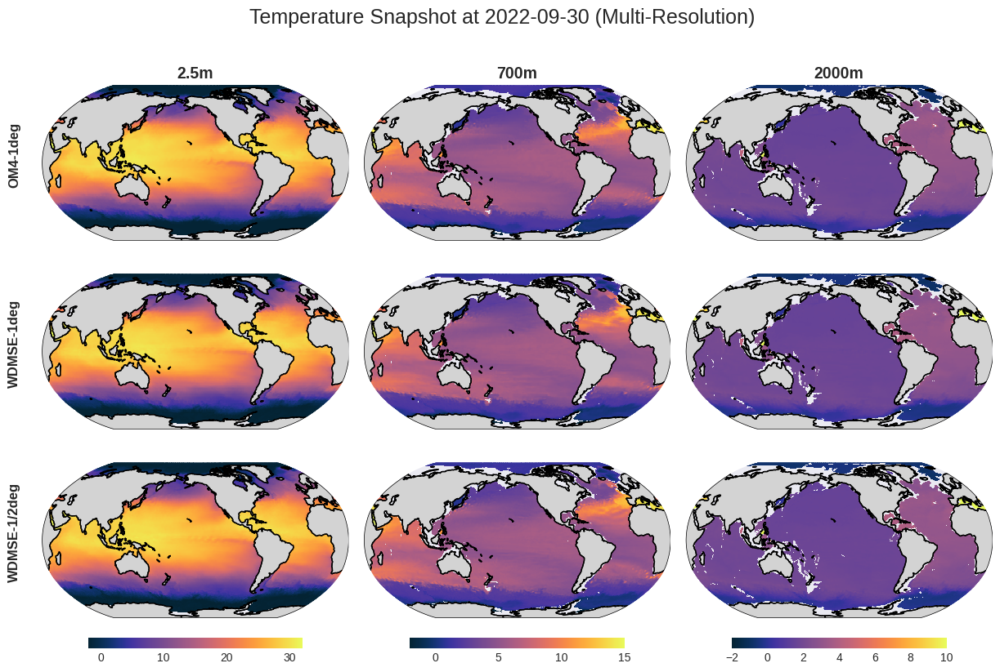

In [87]:
from functions import *
# --- Configuration ---
VARIABLE_TO_PLOT = 'thetao'  # Options: 'thetao', 'so', 'zos', 'uo', 'vo'

# # --- Execution ---
# for depth in [0,1,2,3]:
    
#     plot_snapshot_comparison_SpecificLayer_together(
#         emulators_to_analyze, 
#         var_name=VARIABLE_TO_PLOT, 
#         time_indices=TIME_INDICES,
#         depth_config=DEPTH_LAYERS[depth],
#         fix_colorbar=True
#     )

plot_snapshot_comparison_multidepth_together(
    emulators_to_analyze, 
    var_name=VARIABLE_TO_PLOT, 
    time_indices=TIME_INDICES,
    depth_configs=DEPTH_LAYERS,  # Pass the entire list of depths here
    fix_colorbar=True
)

In [ ]:
DEPTH_LAYERS[3]

In [ ]:
DEPTH_LAYERS


Generating OHC Snapshot Comparison (Multi-Resolution, Multi-Depth)...


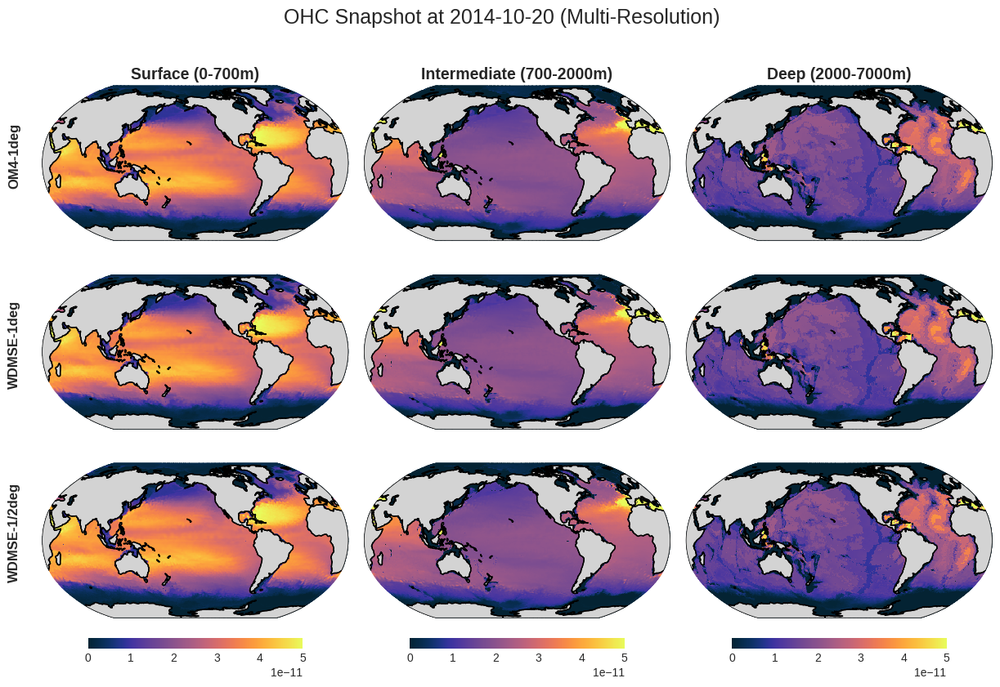

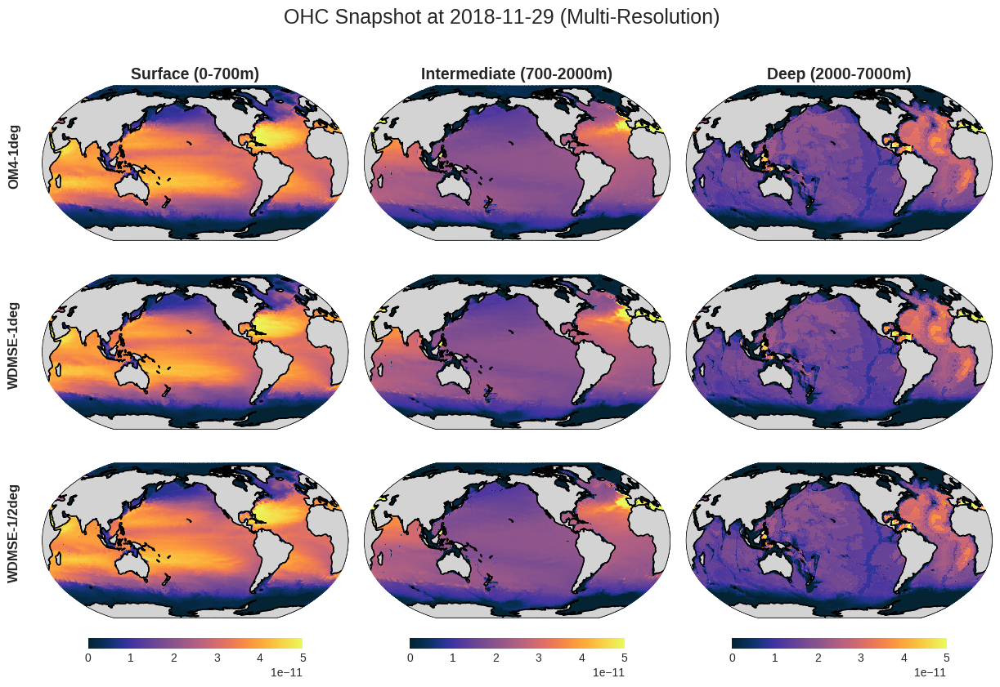

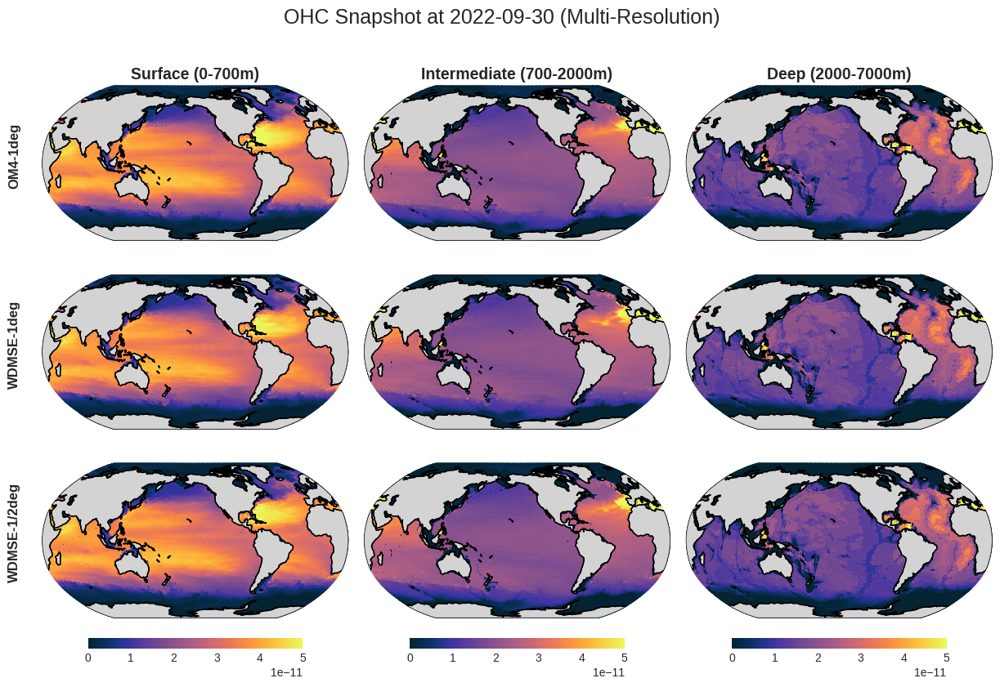

In [ ]:
from functions import *

VARIABLE_TO_PLOT = 'thetao'

# for depth in [0,1,2]:

#     # --- Execution ---
#     plot_ohc_snapshot_comparison_together(
#         emulators_to_analyze, 
#         var_name=VARIABLE_TO_PLOT, 
#         time_indices=TIME_INDICES,
#         depth_config=DEPTH_SLICES[depth],
#         colorbar_fix=True
#     )

plot_ohc_snapshot_comparison_multidepth_together(
    emulators_to_analyze, 
    time_indices=TIME_INDICES,
    depth_configs=DEPTH_SLICES,  # Pass the list of depth slices
    colorbar_fix=True
)